In [1]:
import sys
import os
import importlib
import numpy as np
from cmcrameri import cm
import matplotlib.pyplot as plt

In [2]:
GRAVMAG_PARENT = os.environ.get("GRAVMAG_PARENT")

In [3]:
if GRAVMAG_PARENT and GRAVMAG_PARENT not in sys.path:
    sys.path.insert(0, GRAVMAG_PARENT)

In [4]:
from gravmag import filtering
from gravmag import derivative
from gravmag import grids
from gravmag import synthetic
from gravmag import prism

In [5]:
importlib.reload(derivative)
importlib.reload(filtering)
importlib.reload(grids)
importlib.reload(prism)
importlib.reload(synthetic)

<module 'gravmag.synthetic' from 'C:\\Users\\Usuario\\Python_Notebooks\\python\\geophysics\\gravmag\\synthetic.py'>

In [6]:
area = [-5000.0, 5000.0, -5000.0, 5000.0]
shape = (201, 201)
x, y, z = synthetic.my_make_observation_grid(
    area=area,
    shape=shape,
    level=0.0,
    flatten=False)
dx_grid = np.mean(np.diff(x[0, :]))
dy_grid = np.mean(np.diff(y[:, 0]))

prisms = synthetic.my_synthetic_prism_model(
    centers_x=[0.0],
    centers_y=[0.0],
    top=250.0,
    bottom=1250.0,
    dx=2000.0,
    dy=2000.0,
    density=0.30)

print("Grid shape:", x.shape)
print(f"dx = {dx_grid:.2f} m")
print(f"dy = {dy_grid:.2f} m")
print("Prism:")
print(prisms[0])

Grid shape: (201, 201)
dx = 50.00 m
dy = 50.00 m
Prism:
[-1000.0, 1000.0, -1000.0, 1000.0, 250.0, 1250.0, 0.3]


In [7]:
gz = synthetic.my_forward_prisms_gz(
    x=x,
    y=y,
    z=z,
    prisms=prisms
)

print("Gravity anomaly calculated successfully.")
print("Shape:", gz.shape)
print(f"Minimum gz = {np.nanmin(gz):.6f} mGal")
print(f"Maximum gz = {np.nanmax(gz):.6f} mGal")
print(f"Amplitude   = {np.nanmax(gz) - np.nanmin(gz):.6f} mGal")

Gravity anomaly calculated successfully.
Shape: (201, 201)
Minimum gz = 0.017082 mGal
Maximum gz = 5.885844 mGal
Amplitude   = 5.868762 mGal


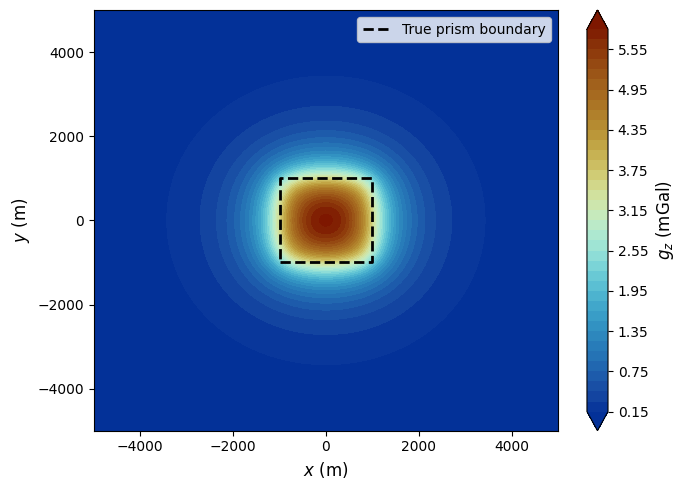

In [8]:
n_levels = 40
plt.figure(figsize=(7, 5))
cf = plt.contourf(
    x,
    y,
    gz,
    levels=n_levels,
    cmap=cm.roma_r,
    #cmap="RdBu_r",
    extend="both")

cbar = plt.colorbar(cf)
cbar.set_label(r"$g_z$ (mGal)", fontsize=12)

plt.plot(
    [-1000, 1000, 1000, -1000, -1000],
    [-1000, -1000, 1000, 1000, -1000],
    "k--",
    linewidth=2.0,
    label="True prism boundary")

plt.xlabel("$x$ (m)", fontsize=12)
plt.ylabel("$y$ (m)", fontsize=12)

#plt.axis("equal")
plt.xlim(np.nanmin(x), np.nanmax(x))
plt.ylim(np.nanmin(y), np.nanmax(y))

plt.legend(loc="upper right",frameon=True)

plt.tight_layout()
plt.show()

In [9]:
components_v1 = filtering.my_cgtp_grid(
    x=x,
    y=y,
    data=gz,
    pad_factor=0.5,
    pad_mode="reflect",
    taper=True,
    alpha=1.0,
    beta=1.0,
    sigma_tilt=np.deg2rad(12.0),
    return_components=True
)

dx = components_v1["dx"]
dy = components_v1["dy"]
dz = components_v1["dz"]
hgm = components_v1["hgm"]
asa = components_v1["asa"]
tdr = components_v1["tdr"]
thdr_tdr = components_v1["thdr_tdr"]
theta_ratio = components_v1["theta_ratio"]
edge_weight = components_v1["edge_weight"]
cgtp_v1 = components_v1["cgtp"]

In [10]:
cos_tdr = np.cos(tdr)
difference = theta_ratio - cos_tdr
mask = (
    np.isfinite(theta_ratio)
    & np.isfinite(cos_tdr))

max_abs_difference = np.max(
    np.abs(difference[mask]))

mean_abs_difference = np.mean(
    np.abs(difference[mask]))

rmse_difference = np.sqrt(
    np.mean(difference[mask]**2))

correlation = np.corrcoef(
    theta_ratio[mask].ravel(),
    cos_tdr[mask].ravel())[0, 1]

print("Comparison: HGM/ASA versus cos(TDR)")
print(f"Maximum absolute difference = {max_abs_difference:.12e}")
print(f"Mean absolute difference    = {mean_abs_difference:.12e}")
print(f"RMSE                        = {rmse_difference:.12e}")
print(f"Correlation                 = {correlation:.15f}")

Comparison: HGM/ASA versus cos(TDR)
Maximum absolute difference = 9.491742669621e-09
Mean absolute difference    = 5.289569165106e-09
RMSE                        = 6.020596251744e-09
Correlation                 = 1.000000000000000


In [11]:
asa_exact = np.sqrt(
    hgm**2 + dz**2)

valid = asa_exact > 1.0e-12
ratio_exact = np.zeros_like(hgm)
ratio_exact[valid] = (hgm[valid] / asa_exact[valid])

tdr_exact = np.arctan2(dz,hgm)

cos_tdr_exact = np.cos(tdr_exact)

difference_exact = (ratio_exact[valid]-cos_tdr_exact[valid])

print("Exact identity test")
print("-------------------")

print("Maximum absolute difference =",
    np.max(np.abs(difference_exact)))

print("RMSE =",np.sqrt(np.mean(difference_exact**2)))

Exact identity test
-------------------
Maximum absolute difference = 2.220446049250313e-16
RMSE = 6.674608671694582e-17


In [12]:
levels_v1 = (0.0,250.0,500.0,1000.0)

ms_components_v1 = filtering.my_multiscale_cgtp_grid(
    x=x,
    y=y,
    data=gz,
    upward_levels=levels_v1,
    pad_factor=0.5,
    pad_mode="reflect",
    taper=True,
    alpha=1.0,
    beta=1.0,
    sigma_tilt=np.deg2rad(12.0),
    return_components=True)

ms_cgtp_v1 = ms_components_v1["ms_cgtp"]
persistence_v1 = ms_components_v1["persistence"]
mean_cgtp_v1 = ms_components_v1["mean_cgtp"]
std_cgtp_v1 = ms_components_v1["std_cgtp"]

print("MS-CGTP V1 calculated.")
print("Continuation levels:", ms_components_v1["levels"])

print(
    f"MS-CGTP range: "
    f"{np.nanmin(ms_cgtp_v1):.6f} - "
    f"{np.nanmax(ms_cgtp_v1):.6f}")
print(
    f"Persistence range: "
    f"{np.nanmin(persistence_v1):.6f} - "
    f"{np.nanmax(persistence_v1):.6f}")

MS-CGTP V1 calculated.
Continuation levels: (0.0, 250.0, 500.0, 1000.0)
MS-CGTP range: 0.000000 - 1.000000
Persistence range: 0.000000 - 1.000000


In [13]:
components_v1 = filtering.my_cgtp_grid(
    x=x,
    y=y,
    data=gz,
    pad_factor=0.5,
    pad_mode="reflect",
    taper=True,
    alpha=1.0,
    beta=1.0,
    sigma_tilt=np.deg2rad(12.0),
    return_components=True
)

# Individual components
dx = components_v1["dx"]
dy = components_v1["dy"]
dz = components_v1["dz"]

hgm = components_v1["hgm"]
asa = components_v1["asa"]

tdr = components_v1["tdr"]
thdr_tdr = components_v1["thdr_tdr"]

theta_ratio = components_v1["theta_ratio"]
edge_weight = components_v1["edge_weight"]

cgtp_v1 = components_v1["cgtp"]

print("CGTP V1 components calculated successfully.")
print("\nAvailable components:")

for key in components_v1.keys():
    print(f" - {key}")

print("\nBasic ranges:")
print(f"HGM        : {np.nanmin(hgm):.6e} to {np.nanmax(hgm):.6e}")
print(f"ASA        : {np.nanmin(asa):.6e} to {np.nanmax(asa):.6e}")
print(f"TDR        : {np.nanmin(tdr):.6f} to {np.nanmax(tdr):.6f} rad")
print(f"THDR-TDR   : {np.nanmin(thdr_tdr):.6e} to {np.nanmax(thdr_tdr):.6e}")
print(f"HGM / ASA  : {np.nanmin(theta_ratio):.6f} to {np.nanmax(theta_ratio):.6f}")
print(f"CGTP V1    : {np.nanmin(cgtp_v1):.6f} to {np.nanmax(cgtp_v1):.6f}")

CGTP V1 components calculated successfully.

Available components:
 - dx
 - dy
 - dz
 - hgm
 - asa
 - tdr
 - tdr_dx
 - tdr_dy
 - thdr_tdr
 - theta_ratio
 - edge_weight
 - theta_ratio_normalized
 - thdr_tdr_normalized
 - cgtp

Basic ranges:
HGM        : 5.206504e-16 to 5.190929e-03
ASA        : 1.156508e-04 to 6.715608e-03
TDR        : -1.570594 to 1.570796 rad
THDR-TDR   : 7.789370e-15 to 2.842409e-03
HGM / ASA  : 0.000000 to 1.000000
CGTP V1    : 0.000000 to 1.000000


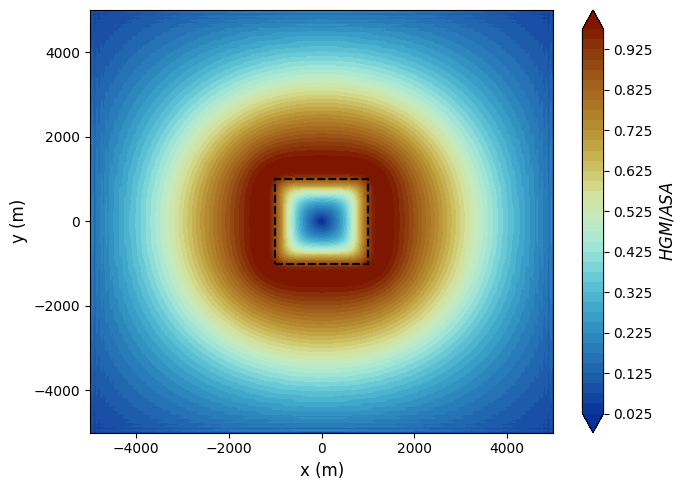

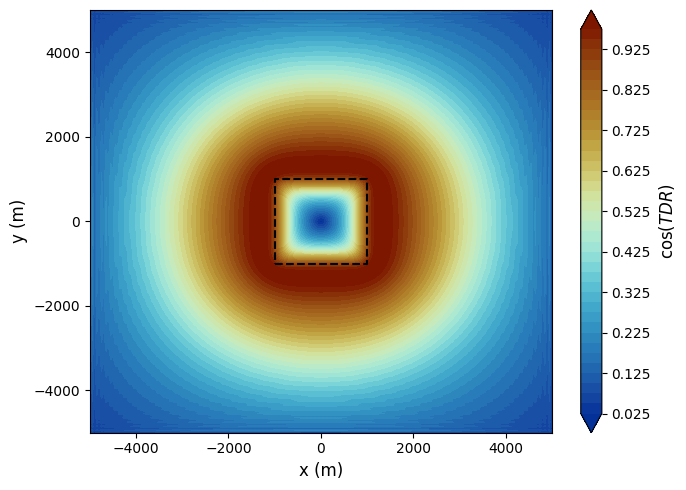

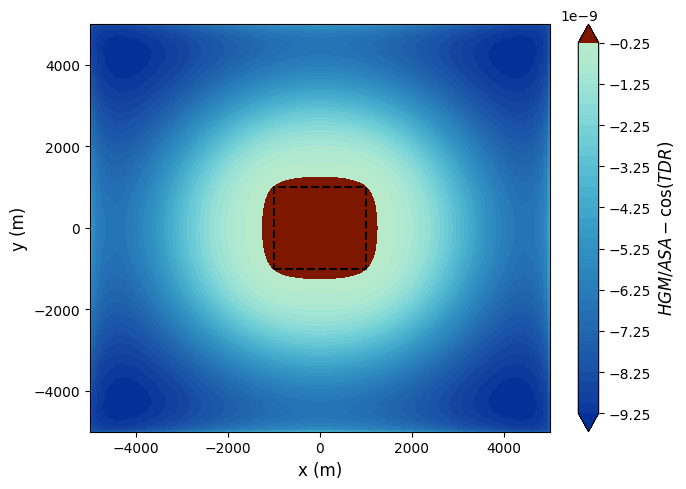

In [14]:
cos_tdr = np.cos(tdr)
difference = theta_ratio - cos_tdr

plt.figure(figsize=(7, 5))
cf = plt.contourf(
    x,
    y,
    theta_ratio,
    levels=40,
    cmap=cm.roma_r,
    extend="both")
cbar = plt.colorbar(cf)
cbar.set_label(r"$HGM/ASA$", fontsize=12)

plt.plot(
    [-1000, 1000, 1000, -1000, -1000],
    [-1000, -1000, 1000, 1000, -1000],
    "k--",
    linewidth=1.5)

plt.xlabel("x (m)", fontsize=12)
plt.ylabel("y (m)", fontsize=12)
#plt.axis("equal")
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 5))
cf = plt.contourf(
    x,
    y,
    cos_tdr,
    levels=40,
    cmap=cm.roma_r,
    extend="both")

cbar = plt.colorbar(cf)
cbar.set_label(r"$\cos(TDR)$", fontsize=12)

plt.plot(
    [-1000, 1000, 1000, -1000, -1000],
    [-1000, -1000, 1000, 1000, -1000],
    "k--",
    linewidth=1.5)

plt.xlabel("x (m)", fontsize=12)
plt.ylabel("y (m)", fontsize=12)
#plt.axis("equal")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
max_diff_plot = np.nanmax(np.abs(difference))

cf = plt.contourf(
    x,
    y,
    difference,
    levels=40,
    cmap=cm.roma_r,
    vmin=-max_diff_plot,
    vmax=max_diff_plot,
    extend="both"
)

cbar = plt.colorbar(cf)
cbar.set_label(
    r"$HGM/ASA-\cos(TDR)$",
    fontsize=12)

plt.plot(
    [-1000, 1000, 1000, -1000, -1000],
    [-1000, -1000, 1000, 1000, -1000],
    "k--",
    linewidth=1.5)

plt.xlabel("x (m)", fontsize=12)
plt.ylabel("y (m)", fontsize=12)
#plt.axis("equal")
plt.tight_layout()
plt.show()

In [15]:
mask = (np.isfinite(theta_ratio)
    & np.isfinite(cos_tdr))

ratio_valid = theta_ratio[mask]
cos_valid = cos_tdr[mask]

difference_valid = (ratio_valid - cos_valid)

max_abs_difference = np.max(np.abs(difference_valid))
mean_abs_difference = np.mean(np.abs(difference_valid))

rmse_difference = np.sqrt(np.mean(difference_valid**2))

correlation = np.corrcoef(ratio_valid.ravel(),cos_valid.ravel())[0, 1]

print("HGM / ASA versus cos(TDR)")
print(f"Maximum absolute difference : "
    f"{max_abs_difference:.10f}")
print(f"Mean absolute difference    : "
    f"{mean_abs_difference:.10f}")
print(f"RMSE                        : "
    f"{rmse_difference:.10f}")
print(f"Correlation coefficient     : "
    f"{correlation:.10f}")

HGM / ASA versus cos(TDR)
Maximum absolute difference : 0.0000000095
Mean absolute difference    : 0.0000000053
RMSE                        : 0.0000000060
Correlation coefficient     : 1.0000000000


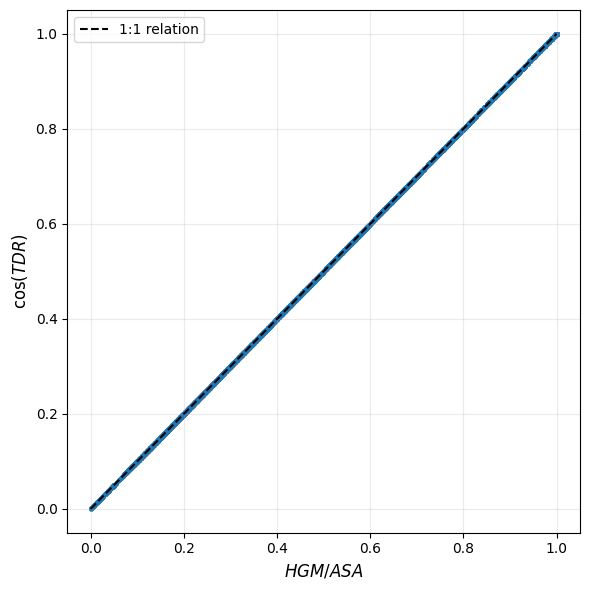

In [16]:
plt.figure(figsize=(6, 6))
plt.scatter(ratio_valid,cos_valid,s=5,alpha=0.25)
minimum = min(np.min(ratio_valid),np.min(cos_valid))
maximum = max(np.max(ratio_valid),np.max(cos_valid))
plt.plot([minimum, maximum],[minimum, maximum],"k--", linewidth=1.5, label="1:1 relation")
plt.xlabel(r"$HGM/ASA$", fontsize=12)
plt.ylabel(r"$\cos(TDR)$", fontsize=12)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [17]:
asa_exact = np.sqrt(hgm**2 + dz**2)

valid_exact = (np.isfinite(asa_exact)
    & (asa_exact > 1.0e-14))

ratio_exact = np.full_like(hgm,np.nan,dtype=float)

ratio_exact[valid_exact] = (hgm[valid_exact]/asa_exact[valid_exact])

tdr_exact = np.arctan2(dz,hgm)

cos_tdr_exact = np.cos(tdr_exact)

difference_exact = (ratio_exact[valid_exact]-cos_tdr_exact[valid_exact])

max_difference_exact = np.max(np.abs(difference_exact))

mean_difference_exact = np.mean(np.abs(difference_exact))

rmse_exact = np.sqrt(np.mean(difference_exact**2))

print(" EXACT MATHEMATICAL IDENTITY")
print(f"Maximum absolute difference : "
    f"{max_difference_exact:.10e}")
print(f"Mean absolute difference    : "
    f"{mean_difference_exact:.10e}")
print(f"RMSE                        : "
    f"{rmse_exact:.10e}")

 EXACT MATHEMATICAL IDENTITY
Maximum absolute difference : 2.2204460493e-16
Mean absolute difference    : 4.9882649569e-17
RMSE                        : 6.6746086717e-17


## Mathematical relation between HGM/ASA and the tilt angle

The horizontal gradient magnitude is

$$
HGM =
\sqrt{
\left(\frac{\partial f}{\partial x}\right)^2
+
\left(\frac{\partial f}{\partial y}\right)^2
}.
$$

The analytic signal amplitude is

$$
ASA =
\sqrt{
HGM^2
+
\left(\frac{\partial f}{\partial z}\right)^2
}.
$$

The tilt derivative is defined as

$$
TDR =
\tan^{-1}
\left(
\frac{
\partial f/\partial z
}{
HGM
}
\right).
$$

Therefore,

$$
\tan(TDR)
=
\frac{
\partial f/\partial z
}{
HGM
}.
$$

Using

$$
1+\tan^2(\theta)=\sec^2(\theta),
$$

we obtain

$$
\cos(TDR)
=
\frac{1}{
\sqrt{
1+
\left(
\frac{
\partial f/\partial z
}{
HGM
}
\right)^2
}
}.
$$

Multiplying the numerator and denominator by \(HGM\),

$$
\cos(TDR)
=
\frac{
HGM
}{
\sqrt{
HGM^2
+
\left(
\partial f/\partial z
\right)^2
}
}.
$$

Since

$$
ASA =
\sqrt{
HGM^2+
\left(
\partial f/\partial z
\right)^2
},
$$

it follows that

$$
\boxed{
\frac{HGM}{ASA}
=
\cos(TDR)
}.
$$

Therefore, the gradient-ratio term used in the original CGTP
formulation is not mathematically independent from the tilt angle.

In [18]:
from scipy.ndimage import gaussian_filter
def finite_percentile(data, q):
    """
    Percentile calculated only over finite values.
    """
    data = np.asarray(data, dtype=float)
    values = data[np.isfinite(data)]
    
    return np.percentile(values, q)

In [19]:
# Numerical stabilizer
eps_g = 1.0e-12
q75_hgm = finite_percentile(hgm, 75.0)
q99_hgm = finite_percentile(hgm, 99.0)
print("Robust HGM reference values")
print("---------------------------")
print(f"75th percentile = {q75_hgm:.6e}")
print(f"99th percentile = {q99_hgm:.6e}")

G1 = np.clip(hgm / (q99_hgm + eps_g),0.0,1.0)
G2 = (hgm/(hgm + q75_hgm + eps_g))
G3_raw = np.log1p(hgm / (q75_hgm + eps_g))
G3_reference = np.log1p( q99_hgm / (q75_hgm + eps_g))
G3 = np.clip(G3_raw / (G3_reference + eps_g),0.0,1.0)

local_scale_m = 500.0
sigma_pixels = local_scale_m / dx_grid
local_rms_hgm = np.sqrt(gaussian_filter(hgm**2,sigma=sigma_pixels,mode="reflect"))
relative_gradient = (hgm/(local_rms_hgm + eps_g))
G4 = (relative_gradient/(1.0 + relative_gradient))

print("\nCandidate ranges")
print("----------------")
print(f"G1 = {np.nanmin(G1):.6f} to {np.nanmax(G1):.6f}")
print(f"G2 = {np.nanmin(G2):.6f} to {np.nanmax(G2):.6f}")
print(f"G3 = {np.nanmin(G3):.6f} to {np.nanmax(G3):.6f}")
print(f"G4 = {np.nanmin(G4):.6f} to {np.nanmax(G4):.6f}")

Robust HGM reference values
---------------------------
75th percentile = 2.822002e-04
99th percentile = 4.802608e-03

Candidate ranges
----------------
G1 = 0.000000 to 1.000000
G2 = 0.000000 to 0.948439
G3 = 0.000000 to 1.000000
G4 = 0.000000 to 0.596417


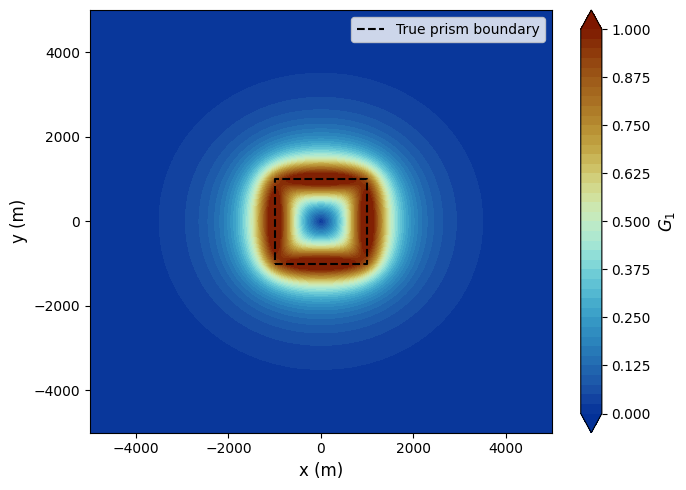

In [20]:
plt.figure(figsize=(7, 5))

cf = plt.contourf(x,y,G1,levels=np.linspace(0.0, 1.0, 41),cmap=cm.roma_r,extend="both")
cbar = plt.colorbar(cf)
cbar.set_label(r"$G_1$", fontsize=12)
plt.plot(
    [-1000, 1000, 1000, -1000, -1000],
    [-1000, -1000, 1000, 1000, -1000],
    "k--",
    linewidth=1.5,
    label="True prism boundary"
)
plt.xlabel("x (m)", fontsize=12)
plt.ylabel("y (m)", fontsize=12)

plt.legend()
plt.tight_layout()
plt.show()

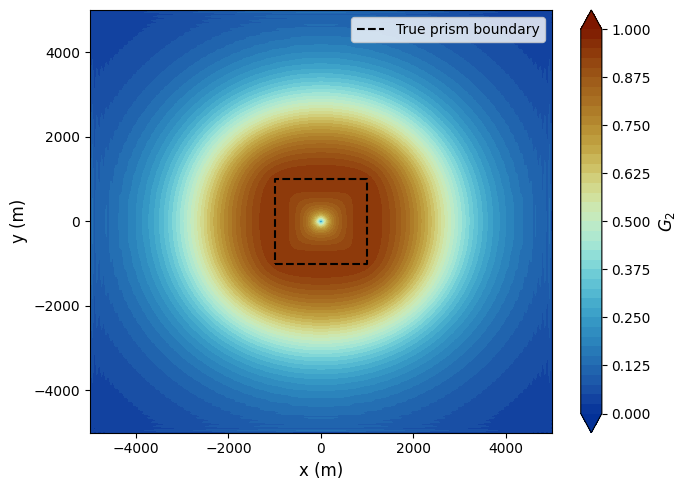

In [21]:
plt.figure(figsize=(7, 5))

cf = plt.contourf(x,y,G2,levels=np.linspace(0.0, 1.0, 41),cmap=cm.roma_r,extend="both")
cbar = plt.colorbar(cf)
cbar.set_label(r"$G_2$", fontsize=12)
plt.plot(
    [-1000, 1000, 1000, -1000, -1000],
    [-1000, -1000, 1000, 1000, -1000],
    "k--",
    linewidth=1.5,
    label="True prism boundary"
)
plt.xlabel("x (m)", fontsize=12)
plt.ylabel("y (m)", fontsize=12)

plt.legend()
plt.tight_layout()
plt.show()

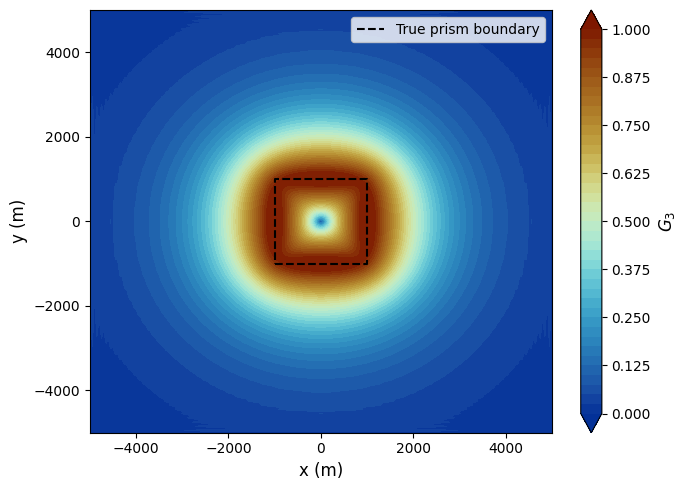

In [22]:
plt.figure(figsize=(7, 5))

cf = plt.contourf(x,y,G3,levels=np.linspace(0.0, 1.0, 41),cmap=cm.roma_r,extend="both")
cbar = plt.colorbar(cf)
cbar.set_label(r"$G_3$", fontsize=12)
plt.plot(
    [-1000, 1000, 1000, -1000, -1000],
    [-1000, -1000, 1000, 1000, -1000],
    "k--",
    linewidth=1.5,
    label="True prism boundary"
)
plt.xlabel("x (m)", fontsize=12)
plt.ylabel("y (m)", fontsize=12)

plt.legend()
plt.tight_layout()
plt.show()

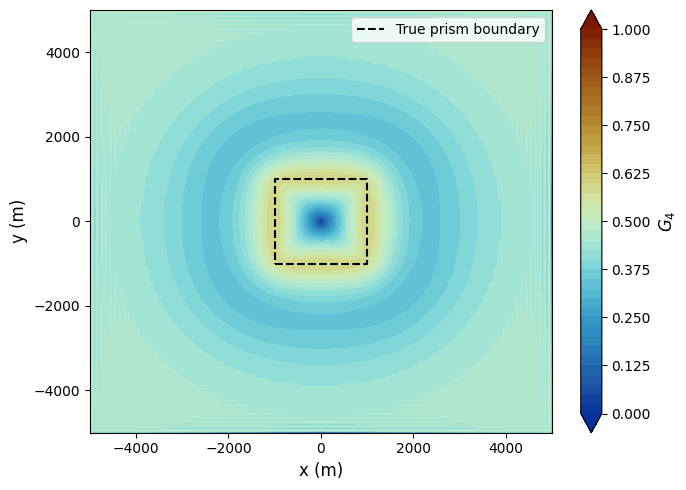

In [23]:
plt.figure(figsize=(7, 5))

cf = plt.contourf(x,y,G4,levels=np.linspace(0.0, 1.0, 41),cmap=cm.roma_r,extend="both")
cbar = plt.colorbar(cf)
cbar.set_label(r"$G_4$", fontsize=12)
plt.plot(
    [-1000, 1000, 1000, -1000, -1000],
    [-1000, -1000, 1000, 1000, -1000],
    "k--",
    linewidth=1.5,
    label="True prism boundary"
)
plt.xlabel("x (m)", fontsize=12)
plt.ylabel("y (m)", fontsize=12)

plt.legend()
plt.tight_layout()
plt.show()

In [24]:
edge_tolerance = 100.0
vertical_edges = ((np.abs(np.abs(x) - 1000.0) <= edge_tolerance) & (np.abs(y) <= 1000.0 + edge_tolerance))
horizontal_edges = ((np.abs(np.abs(y) - 1000.0) <= edge_tolerance) & (np.abs(x) <= 1000.0 + edge_tolerance))

true_edge_mask = (vertical_edges | horizontal_edges)
background_mask = ((np.abs(x) >= 2500.0) | (np.abs(y) >= 2500.0))

In [25]:
def diagnostic_metrics(G, edge_mask, background_mask):
    
    edge_values = G[
        edge_mask & np.isfinite(G)
    ]
    
    background_values = G[
        background_mask & np.isfinite(G)
    ]
    
    edge_mean = np.mean(edge_values)
    edge_median = np.median(edge_values)
    
    background_mean = np.mean(background_values)
    background_median = np.median(background_values)
    
    contrast = (
        edge_mean
        /
        (background_mean + 1.0e-12)
    )
    
    return {
        "edge_mean": edge_mean,
        "edge_median": edge_median,
        "background_mean": background_mean,
        "background_median": background_median,
        "edge_background_ratio": contrast
    }

In [26]:
results_G = {}

for name, G in {
    "G1": G1,
    "G2": G2,
    "G3": G3,
    "G4": G4
}.items():
    
    results_G[name] = diagnostic_metrics(
        G,
        true_edge_mask,
        background_mask
    )

In [27]:
print(" Candidate gradient-strength diagnostics")
for name, result in results_G.items():
    
    print(f"{name}")
    
    print(f"  Edge mean             = "
        f"{result['edge_mean']:.6f}")   
    print(f"  Edge median           = "
        f"{result['edge_median']:.6f}")
    print(f"  Background mean       = "
        f"{result['background_mean']:.6f}")  
    print(f"  Edge/background ratio = "
        f"{result['edge_background_ratio']:.5f}")

 Candidate gradient-strength diagnostics
G1
  Edge mean             = 0.962320
  Edge median           = 1.000000
  Background mean       = 0.015682
  Edge/background ratio = 61.36348
G2
  Edge mean             = 0.943137
  Edge median           = 0.944674
  Background mean       = 0.183205
  Edge/background ratio = 5.14799
G3
  Edge mean             = 0.986616
  Edge median           = 1.000000
  Background mean       = 0.075352
  Edge/background ratio = 13.09350
G4
  Edge mean             = 0.580326
  Edge median           = 0.581617
  Background mean       = 0.423129
  Edge/background ratio = 1.37151


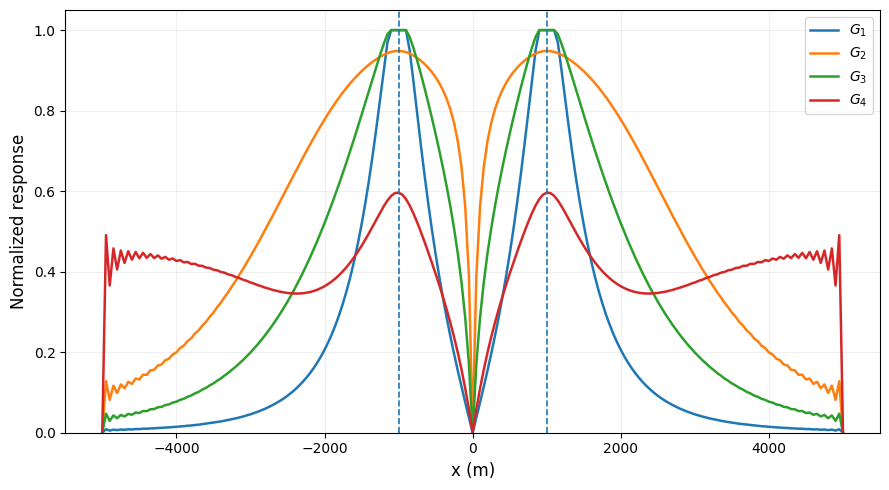

In [28]:
row_center = np.argmin(np.abs(y[:, 0]))
x_profile = x[row_center, :]

plt.figure(figsize=(9, 5))
plt.plot(x_profile,G1[row_center, :],linewidth=1.8,label=r"$G_1$")
plt.plot(x_profile,G2[row_center, :],linewidth=1.8,label=r"$G_2$")
plt.plot(x_profile,G3[row_center, :],linewidth=1.8,label=r"$G_3$")
plt.plot(x_profile,G4[row_center, :],linewidth=1.8,label=r"$G_4$")

plt.axvline(-1000.0,linestyle="--",linewidth=1.2)
plt.axvline(1000.0,linestyle="--",linewidth=1.2)
plt.xlabel("x (m)", fontsize=12)
plt.ylabel("Normalized response", fontsize=12)

plt.ylim(0.0, 1.05)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [29]:
area2 = [-6000.0, 6000.0,-5000.0, 5000.0]

shape2 = (241, 201)

x2, y2, z2 = synthetic.my_make_observation_grid(
    area=area2,
    shape=shape2,
    level=0.0,
    flatten=False)

dx2 = np.mean(np.diff(x2[0, :]))
dy2 = np.mean(np.diff(y2[:, 0]))

print("Grid shape :", x2.shape)
print(f"dx         : {dx2:.2f} m")
print(f"dy         : {dy2:.2f} m")

Grid shape : (201, 241)
dx         : 50.00 m
dy         : 50.00 m


In [30]:
prism_A = [
    -3200.0,   # x_min
    -1600.0,   # x_max
    -800.0,    # y_min
     800.0,    # y_max
     150.0,    # top depth
    1200.0,    # bottom depth
       0.30]    # density contrast (g/cm^3)]

prism_B = [
      900.0,   # x_min
     3500.0,   # x_max
    -1200.0,   # y_min
     1200.0,   # y_max
      600.0,   # top depth
     2000.0,   # bottom depth
        0.15]   # density contrast (g/cm^3)]

prisms2 = [prism_A,prism_B]

In [31]:
gz_A = synthetic.my_forward_prisms_gz(
    x=x2,
    y=y2,
    z=z2,
    prisms=[prism_A])

gz_B = synthetic.my_forward_prisms_gz(
    x=x2,
    y=y2,
    z=z2,
    prisms=[prism_B])

gz2 = gz_A + gz_B

In [32]:
# Peak amplitudes
peak_A = np.nanmax(np.abs(gz_A))
peak_B = np.nanmax(np.abs(gz_B))

peak_ratio = (max(peak_A, peak_B)/min(peak_A, peak_B))


print("Individual gravity responses")
print(f"Prism A peak amplitude = "
    f"{peak_A:.6f} mGal")

print(f"Prism B peak amplitude = "
      f"{peak_B:.6f} mGal")

print(f"Peak amplitude ratio   = "
    f"{peak_ratio:.3f}")

print("Combined field")
print(f"Minimum = "
    f"{np.nanmin(gz2):.6f} mGal")

print(f"Maximum = "
    f"{np.nanmax(gz2):.6f} mGal")

Individual gravity responses
Prism A peak amplitude = 5.783815 mGal
Prism B peak amplitude = 3.019739 mGal
Peak amplitude ratio   = 1.915
Combined field
Minimum = 0.028189 mGal
Maximum = 5.895278 mGal


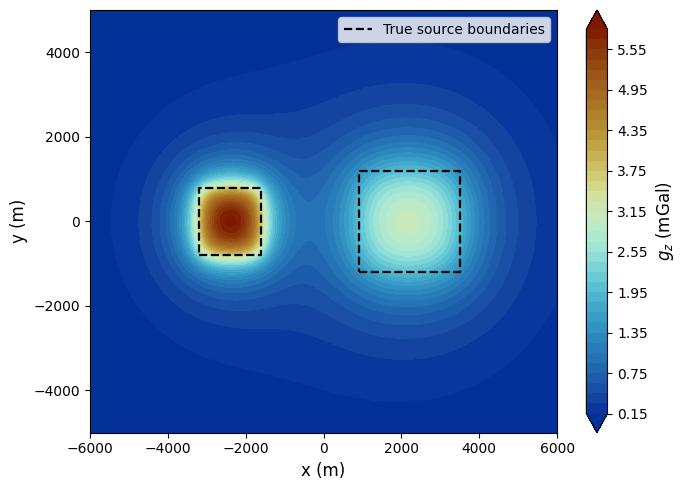

In [33]:
plt.figure(figsize=(7, 5))

cf = plt.contourf(x2,y2,gz2,levels=50,cmap=cm.roma_r,extend="both")
cbar = plt.colorbar(cf)
cbar.set_label(r"$g_z$ (mGal)",fontsize=12)

plt.plot([prism_A[0],prism_A[1],prism_A[1],prism_A[0],prism_A[0]],
         [prism_A[2],prism_A[2],prism_A[3],prism_A[3],prism_A[2]],
         "k--",linewidth=1.6,label="True source boundaries")

plt.plot([prism_B[0],prism_B[1],prism_B[1],prism_B[0],prism_B[0]],
         [prism_B[2],prism_B[2],prism_B[3],prism_B[3],prism_B[2]],
         "k--",linewidth=1.6)

plt.xlabel("x (m)", fontsize=12)
plt.ylabel("y (m)", fontsize=12)
plt.legend()

plt.tight_layout()
plt.show()

In [34]:
components2 = filtering.my_cgtp_grid(x=x2,y=y2,data=gz2,pad_factor=0.5,pad_mode="reflect",taper=True,
                                     alpha=1.0,beta=1.0,sigma_tilt=np.deg2rad(12.0),return_components=True)

hgm2 = components2["hgm"]
tdr2 = components2["tdr"]
theta_ratio2 = components2["theta_ratio"]
G_v1_2 = components2["theta_ratio_normalized"]

q75_hgm2 = finite_percentile(hgm2,75.0)
q99_hgm2 = finite_percentile(hgm2,99.0)

HGM2_norm = (hgm2/(np.nanmax(hgm2) + eps_g))

G1_2 = np.clip(hgm2/(q99_hgm2 + eps_g),0.0,1.0)
G2_2 = (hgm2/(hgm2+q75_hgm2+eps_g))
G3_raw2 = np.log1p(hgm2/(q75_hgm2 + eps_g))
G3_reference2 = np.log1p(q99_hgm2/(q75_hgm2 + eps_g))
G3_2 = np.clip(G3_raw2/(G3_reference2 + eps_g),0.0,1.0)

print("Two-prism robust HGM statistics")
print(f"Q75 = {q75_hgm2:.6e}")
print(f"Q99 = {q99_hgm2:.6e}")

Two-prism robust HGM statistics
Q75 = 5.848640e-04
Q99 = 5.648599e-03


In [35]:
def rectangular_edge_mask(x_grid, y_grid,prism_parameters,tolerance=100.0):    
    xi = prism_parameters[0]
    xf = prism_parameters[1]    
    yi = prism_parameters[2]
    yf = prism_parameters[3]    
    vertical_edges = (((np.abs(x_grid - xi) <= tolerance) | 
                       (np.abs(x_grid - xf) <= tolerance)) & 
                      (y_grid >= yi - tolerance) &
                      (y_grid <= yf + tolerance))    
    
    horizontal_edges = (((np.abs(y_grid - yi) <= tolerance) |
                         (np.abs(y_grid - yf) <= tolerance)) &
                        (x_grid >= xi - tolerance) & 
                        (x_grid <= xf + tolerance))   
    return (vertical_edges | horizontal_edges)

In [36]:
edge_A = rectangular_edge_mask(x2,y2,prism_A,tolerance=100.0)
edge_B = rectangular_edge_mask(x2,y2,prism_B,tolerance=100.0)
background2 = ((np.abs(x2) >= 5000.0) | (np.abs(y2) >= 4000.0))

print("Points in Prism A edge mask:",
    np.sum(edge_A))

print("Points in Prism B edge mask:",
      np.sum(edge_B))

print("Points in background:",
      np.sum(background2))

Points in Prism A edge mask: 640
Points in Prism B edge mask: 1000
Points in background: 16800


In [37]:
def two_source_metrics(response, mask_A, mask_B, background_mask):
    finite = np.isfinite(response)
    values_A = response[mask_A & finite]
    values_B = response[mask_B & finite]
    values_bg = response[background_mask & finite]

    mean_A = np.mean(values_A)
    mean_B = np.mean(values_B)
    background_mean = np.mean(values_bg)

    strong_weak_ratio = max(mean_A, mean_B) / (min(mean_A, mean_B) + 1e-12)
    balance = min(mean_A, mean_B) / (max(mean_A, mean_B) + 1e-12)
    average_edge = 0.5 * (mean_A + mean_B)
    edge_background = average_edge / (background_mean + 1e-12)

    return {
        "A": mean_A,
        "B": mean_B,
        "ratio": strong_weak_ratio,
        "balance": balance,
        "background": background_mean,
        "edge_background": edge_background
    }

In [38]:
responses2 = {
    "HGM": HGM2_norm,
    "G V1": G_v1_2,
    "G1": G1_2,
    "G2": G2_2,
    "G3": G3_2
}

metrics2 = {}

for name, response in responses2.items():
    metrics2[name] = two_source_metrics(response, edge_A, edge_B, background2)

print("TWO-SOURCE GRADIENT-STRENGTH METRICS")

for name, result in metrics2.items():
    print(f"{name}")
    print(f"  Mean edge response A    = {result['A']:.6f}")
    print(f"  Mean edge response B    = {result['B']:.6f}")
    print(f"  Strong/weak ratio       = {result['ratio']:.3f}")
    print(f"  Balance score           = {result['balance']:.3f}")
    print(f"  Background mean         = {result['background']:.6f}")
    print(f"  Edge/background ratio   = {result['edge_background']:.3f}")

TWO-SOURCE GRADIENT-STRENGTH METRICS
HGM
  Mean edge response A    = 0.874541
  Mean edge response B    = 0.224086
  Strong/weak ratio       = 3.903
  Balance score           = 0.256
  Background mean         = 0.010936
  Edge/background ratio   = 50.228
G V1
  Mean edge response A    = 0.875189
  Mean edge response B    = 0.839541
  Strong/weak ratio       = 1.042
  Balance score           = 0.959
  Background mean         = 0.198245
  Edge/background ratio   = 4.325
G1
  Mean edge response A    = 0.974792
  Mean edge response B    = 0.265388
  Strong/weak ratio       = 3.673
  Balance score           = 0.272
  Background mean         = 0.012952
  Edge/background ratio   = 47.875
G2
  Mean edge response A    = 0.908199
  Mean edge response B    = 0.718787
  Strong/weak ratio       = 1.264
  Balance score           = 0.791
  Background mean         = 0.104845
  Edge/background ratio   = 7.759
G3
  Mean edge response A    = 0.989261
  Mean edge response B    = 0.536555
  Strong/weak rat

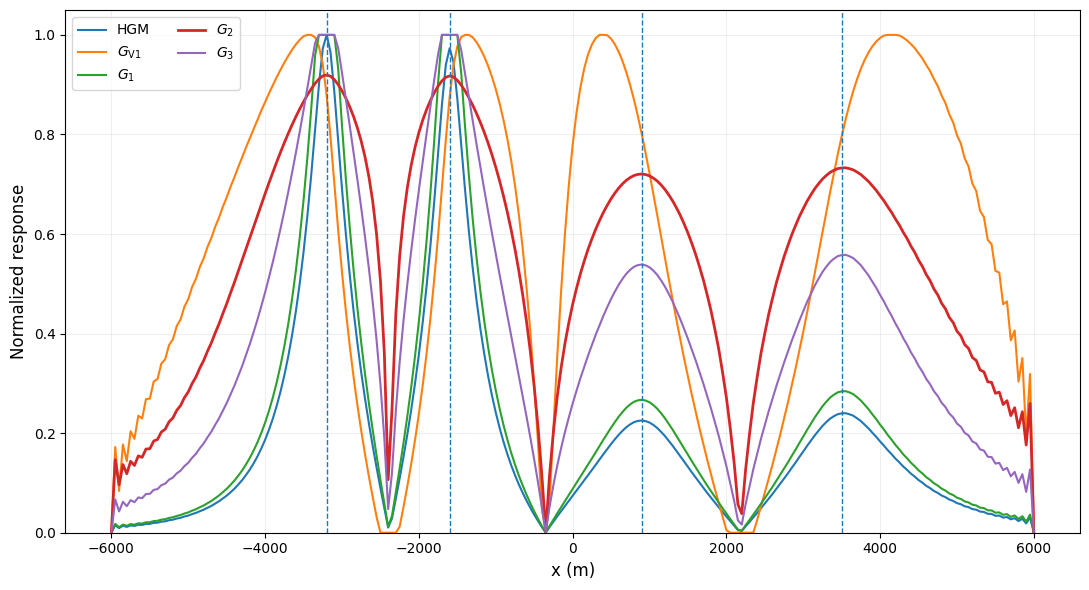

In [39]:
row2 = np.argmin(np.abs(y2[:, 0]))
x_profile2 = x2[row2, :]

plt.figure(figsize=(11, 6))

plt.plot(x_profile2, HGM2_norm[row2, :], linewidth=1.5, label="HGM")
plt.plot(x_profile2, G_v1_2[row2, :], linewidth=1.5, label=r"$G_{\mathrm{V1}}$")
plt.plot(x_profile2, G1_2[row2, :], linewidth=1.5, label=r"$G_1$")
plt.plot(x_profile2, G2_2[row2, :], linewidth=2.0, label=r"$G_2$")
plt.plot(x_profile2, G3_2[row2, :], linewidth=1.5, label=r"$G_3$")

plt.axvline(prism_A[0], linestyle="--", linewidth=1.0)
plt.axvline(prism_A[1], linestyle="--", linewidth=1.0)
plt.axvline(prism_B[0], linestyle="--", linewidth=1.0)
plt.axvline(prism_B[1], linestyle="--", linewidth=1.0)

plt.xlabel("x (m)", fontsize=12)
plt.ylabel("Normalized response", fontsize=12)
plt.ylim(0.0, 1.05)
plt.legend(ncol=2)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [40]:
# Edge-localization error along the central profile
true_edges = np.array([prism_A[0], prism_A[1], prism_B[0], prism_B[1]])
search_halfwidth = 700.0

def edge_localization_errors(xp, response, edges, halfwidth=700.0):
    detected = []
    errors = []
    for edge in edges:
        mask = np.abs(xp - edge) <= halfwidth
        x_local = xp[mask]
        r_local = response[mask]
        x_peak = x_local[np.nanargmax(r_local)]
        detected.append(x_peak)
        errors.append(abs(x_peak - edge))
    return np.array(detected), np.array(errors)

profiles = {
    "HGM": HGM2_norm[row2, :],
    "G V1": G_v1_2[row2, :],
    "G1": G1_2[row2, :],
    "G2": G2_2[row2, :],
    "G3": G3_2[row2, :]
}

localization_results = {}

for name, profile in profiles.items():
    detected, errors = edge_localization_errors(x_profile2, profile, true_edges, search_halfwidth)
    localization_results[name] = {"detected": detected, "errors": errors, "mae": np.mean(errors)}
    print(f"\n{name}")
    print("  Detected edges (m):", detected)
    print("  Errors (m):        ", errors)
    print(f"  Mean error         = {np.mean(errors):.2f} m")


HGM
  Detected edges (m): [-3200. -1600.   900.  3550.]
  Errors (m):         [ 0.  0.  0. 50.]
  Mean error         = 12.50 m

G V1
  Detected edges (m): [-3450. -1400.   350.  4100.]
  Errors (m):         [250. 200. 550. 600.]
  Mean error         = 400.00 m

G1
  Detected edges (m): [-3300. -1700.   900.  3550.]
  Errors (m):         [100. 100.   0.  50.]
  Mean error         = 62.50 m

G2
  Detected edges (m): [-3200. -1600.   900.  3550.]
  Errors (m):         [ 0.  0.  0. 50.]
  Mean error         = 12.50 m

G3
  Detected edges (m): [-3300. -1700.   900.  3550.]
  Errors (m):         [100. 100.   0.  50.]
  Mean error         = 62.50 m


In [41]:
# Combined diagnostic table
print(f"{'Method':<8} {'Balance':>10} {'Edge/BG':>10} {'MAE (m)':>10}")

for name in profiles:
    balance = metrics2[name]["balance"]
    edge_bg = metrics2[name]["edge_background"]
    mae = localization_results[name]["mae"]
    print(f"{name:<8} {balance:>10.3f} {edge_bg:>10.3f} {mae:>10.2f}")

Method      Balance    Edge/BG    MAE (m)
HGM           0.256     50.228      12.50
G V1          0.959      4.325     400.00
G1            0.272     47.875      62.50
G2            0.791      7.759      12.50
G3            0.542     15.818      62.50


In [42]:
# Sensitivity of G2 to the reference percentile
q_values = np.arange(50, 100, 5)
sensitivity_G2 = []

for q in q_values:
    q_ref = finite_percentile(hgm2, q)
    Gq = hgm2 / (hgm2 + q_ref + eps_g)
    metrics_q = two_source_metrics(Gq, edge_A, edge_B, background2)
    detected_q, errors_q = edge_localization_errors(x_profile2, Gq[row2, :], true_edges, search_halfwidth)
    sensitivity_G2.append({
        "q": q,
        "q_ref": q_ref,
        "balance": metrics_q["balance"],
        "edge_background": metrics_q["edge_background"],
        "ratio": metrics_q["ratio"],
        "mae": np.mean(errors_q)
    })

print(f"{'q':>4} {'Balance':>10} {'Edge/BG':>10} {'Ratio':>10} {'MAE (m)':>10}")
print("-" * 50)

for r in sensitivity_G2:
    print(f"{r['q']:>4.0f} {r['balance']:>10.3f} {r['edge_background']:>10.3f} {r['ratio']:>10.3f} {r['mae']:>10.2f}")

   q    Balance    Edge/BG      Ratio    MAE (m)
--------------------------------------------------
  50      0.921      3.567      1.086      12.50
  55      0.905      4.058      1.105      12.50
  60      0.885      4.678      1.130      12.50
  65      0.862      5.413      1.160      12.50
  70      0.832      6.394      1.202      12.50
  75      0.791      7.759      1.264      12.50
  80      0.742      9.562      1.348      12.50
  85      0.688     11.690      1.454      12.50
  90      0.642     13.705      1.559      12.50
  95      0.585     16.448      1.708      12.50


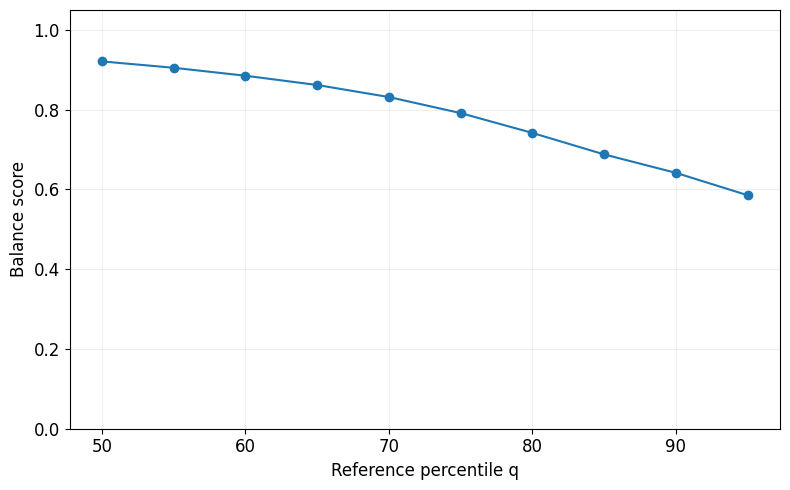

In [43]:
q_plot = np.array([r["q"] for r in sensitivity_G2])
balance_plot = np.array([r["balance"] for r in sensitivity_G2])
contrast_plot = np.array([r["edge_background"] for r in sensitivity_G2])
mae_plot = np.array([r["mae"] for r in sensitivity_G2])

plt.figure(figsize=(8, 5))
plt.plot(q_plot, balance_plot, marker="o", label="Balance score")
plt.xlabel("Reference percentile q", fontsize=12)
plt.ylabel("Balance score", fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.ylim(0, 1.05)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

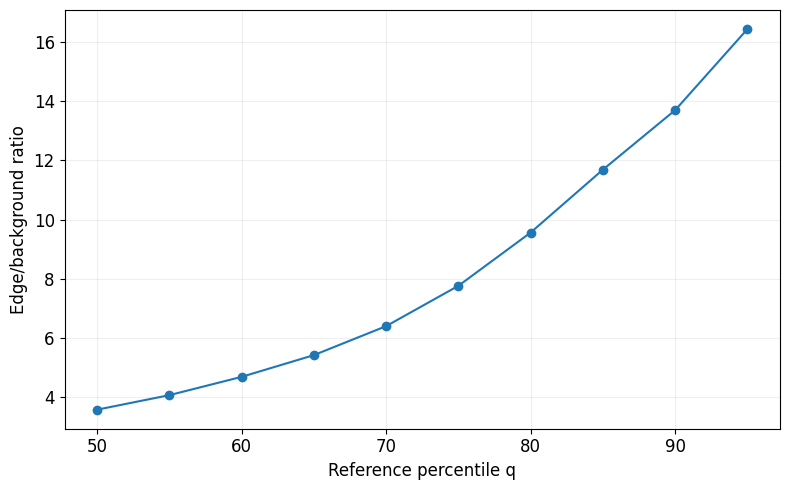

In [44]:
plt.figure(figsize=(8, 5))
plt.plot(q_plot, contrast_plot, marker="o")
plt.xlabel("Reference percentile q",fontsize=12)
plt.ylabel("Edge/background ratio",fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

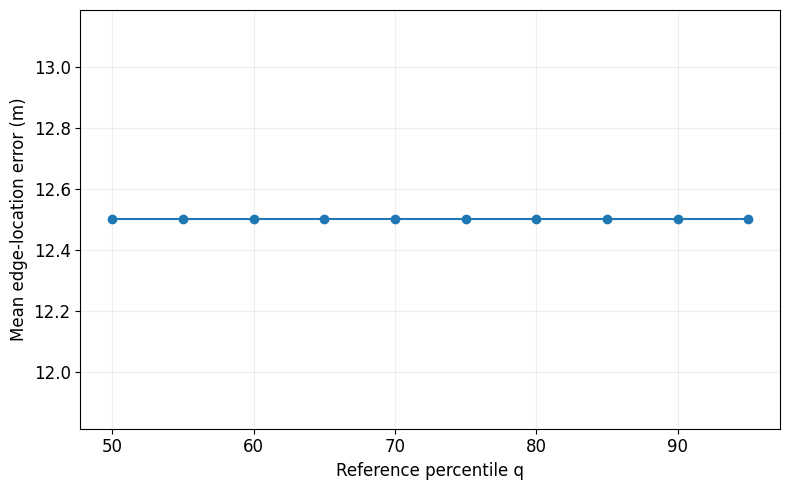

In [45]:
plt.figure(figsize=(8, 5))
plt.plot(q_plot, mae_plot, marker="o")
plt.xlabel("Reference percentile q",fontsize=12)
plt.ylabel("Mean edge-location error (m)",fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [46]:
# Common phase-related terms
T2 = components2["thdr_tdr_normalized"]
W2 = components2["edge_weight"]
CGTP_v1_2 = components2["cgtp"]

q_gradient = 75.0
lambda_g = finite_percentile(hgm2, q_gradient)
G2_final = hgm2 / (hgm2 + lambda_g + eps_g)

print(f"Gradient percentile q = {q_gradient:.1f}")
print(f"lambda_g = Q{q_gradient:.0f}(HGM) = {lambda_g:.6e}")
print(f"T range = {np.nanmin(T2):.6f} to {np.nanmax(T2):.6f}")
print(f"W range = {np.nanmin(W2):.6f} to {np.nanmax(W2):.6f}")

Gradient percentile q = 75.0
lambda_g = Q75(HGM) = 5.848640e-04
T range = 0.000000 to 1.000000
W range = 0.000000 to 0.999998


In [47]:
# Single-scale CGT V2
alpha_v2 = 1.0
beta_v2 = 1.0

CGTP_v2_2 = (G2_final + eps_g)**alpha_v2 * (T2 + eps_g)**beta_v2 * W2
CGTP_v2_2 = CGTP_v2_2 / (np.nanmax(CGTP_v2_2) + eps_g)

print(f"CGTP V1 range = {np.nanmin(CGTP_v1_2):.6f} to {np.nanmax(CGTP_v1_2):.6f}")
print(f"CGTP V2 range = {np.nanmin(CGTP_v2_2):.6f} to {np.nanmax(CGTP_v2_2):.6f}")

CGTP V1 range = 0.000000 to 1.000000
CGTP V2 range = 0.000000 to 1.000000


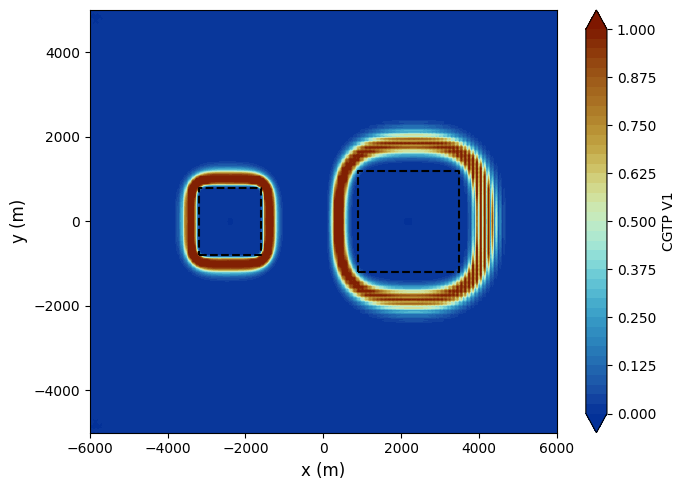

In [48]:
plt.figure(figsize=(7, 5))
cf = plt.contourf(x2, y2, CGTP_v1_2, levels=np.linspace(0, 1, 41), cmap=cm.roma_r, extend="both")
plt.colorbar(cf, label="CGTP V1")
plt.plot([prism_A[0], prism_A[1], prism_A[1], prism_A[0], prism_A[0]], [prism_A[2], prism_A[2], prism_A[3], prism_A[3], prism_A[2]], "k--", linewidth=1.5)
plt.plot([prism_B[0], prism_B[1], prism_B[1], prism_B[0], prism_B[0]], [prism_B[2], prism_B[2], prism_B[3], prism_B[3], prism_B[2]], "k--", linewidth=1.5)
plt.xlabel("x (m)", fontsize=12)
plt.ylabel("y (m)", fontsize=12)
plt.tight_layout()
plt.show()

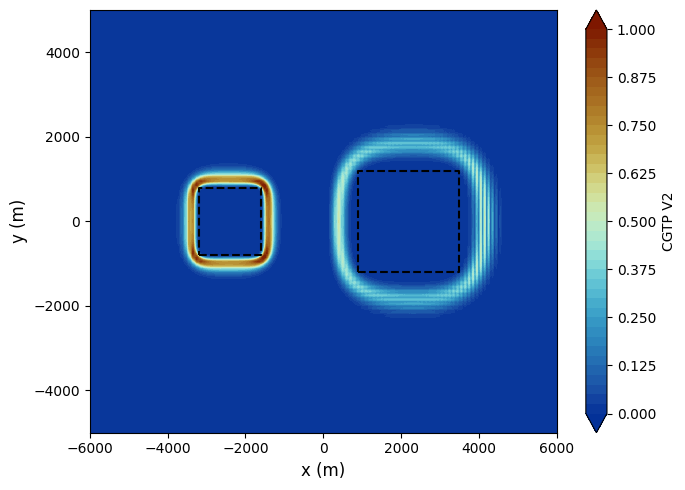

In [49]:
plt.figure(figsize=(7, 5))
cf = plt.contourf(x2, y2, CGTP_v2_2, levels=np.linspace(0, 1, 41), cmap=cm.roma_r, extend="both")
plt.colorbar(cf, label="CGTP V2")
plt.plot([prism_A[0], prism_A[1], prism_A[1], prism_A[0], prism_A[0]], [prism_A[2], prism_A[2], prism_A[3], prism_A[3], prism_A[2]], "k--", linewidth=1.5)
plt.plot([prism_B[0], prism_B[1], prism_B[1], prism_B[0], prism_B[0]], [prism_B[2], prism_B[2], prism_B[3], prism_B[3], prism_B[2]], "k--", linewidth=1.5)
plt.xlabel("x (m)", fontsize=12)
plt.ylabel("y (m)", fontsize=12)
plt.tight_layout()
plt.show()

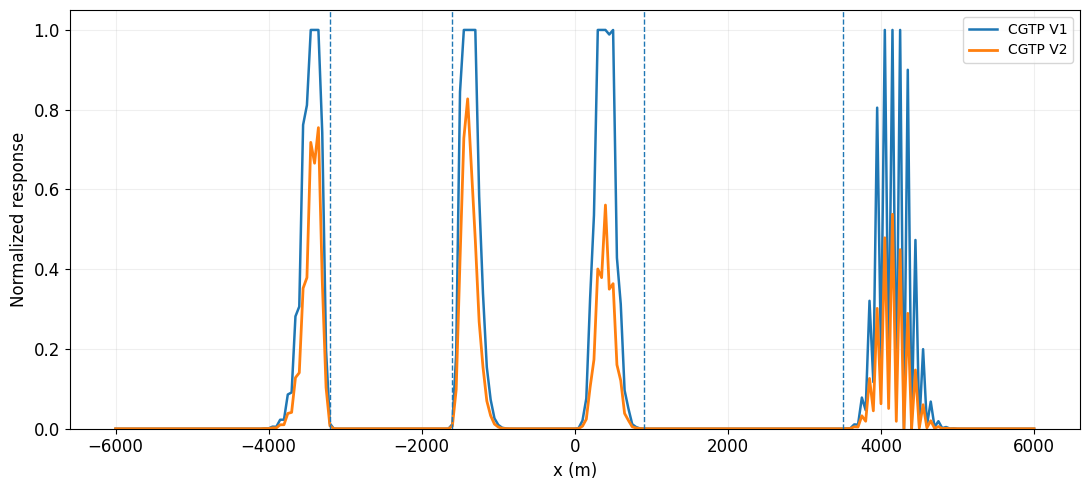

In [50]:
plt.figure(figsize=(11, 5))
plt.plot(x_profile2, CGTP_v1_2[row2, :], linewidth=1.8, label="CGTP V1")
plt.plot(x_profile2, CGTP_v2_2[row2, :], linewidth=2.0, label="CGTP V2")

plt.axvline(prism_A[0], linestyle="--", linewidth=1.0)
plt.axvline(prism_A[1], linestyle="--", linewidth=1.0)
plt.axvline(prism_B[0], linestyle="--", linewidth=1.0)
plt.axvline(prism_B[1], linestyle="--", linewidth=1.0)

plt.xlabel("x (m)", fontsize=12)
plt.ylabel("Normalized response",fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [51]:
responses_cgtp = {"CGTP V1": CGTP_v1_2,"CGTP V2": CGTP_v2_2}

for name, response in responses_cgtp.items():
    metrics = two_source_metrics(response, edge_A, edge_B, background2)
    detected, errors = edge_localization_errors(x_profile2, response[row2, :], true_edges, search_halfwidth)
    print(f"{name}")
    print(f"  Mean edge response A  = {metrics['A']:.6f}")
    print(f"  Mean edge response B  = {metrics['B']:.6f}")
    print(f"  Balance score         = {metrics['balance']:.3f}")
    print(f"  Edge/background ratio = {metrics['edge_background']:.3f}")
    print(f"  Detected edges (m)    = {detected}")
    print(f"  Errors (m)            = {errors}")
    print(f"  Mean edge error       = {np.mean(errors):.2f} m")

CGTP V1
  Mean edge response A  = 0.280809
  Mean edge response B  = 0.021217
  Balance score         = 0.076
  Edge/background ratio = 518756.828
  Detected edges (m)    = [-3450. -1450.   300.  4050.]
  Errors (m)            = [250. 150. 600. 550.]
  Mean edge error       = 387.50 m
CGTP V2
  Mean edge response A  = 0.167554
  Mean edge response B  = 0.008215
  Balance score         = 0.049
  Edge/background ratio = 1118990.303
  Detected edges (m)    = [-3350. -1400.   400.  4150.]
  Errors (m)            = [150. 200. 500. 650.]
  Mean edge error       = 375.00 m


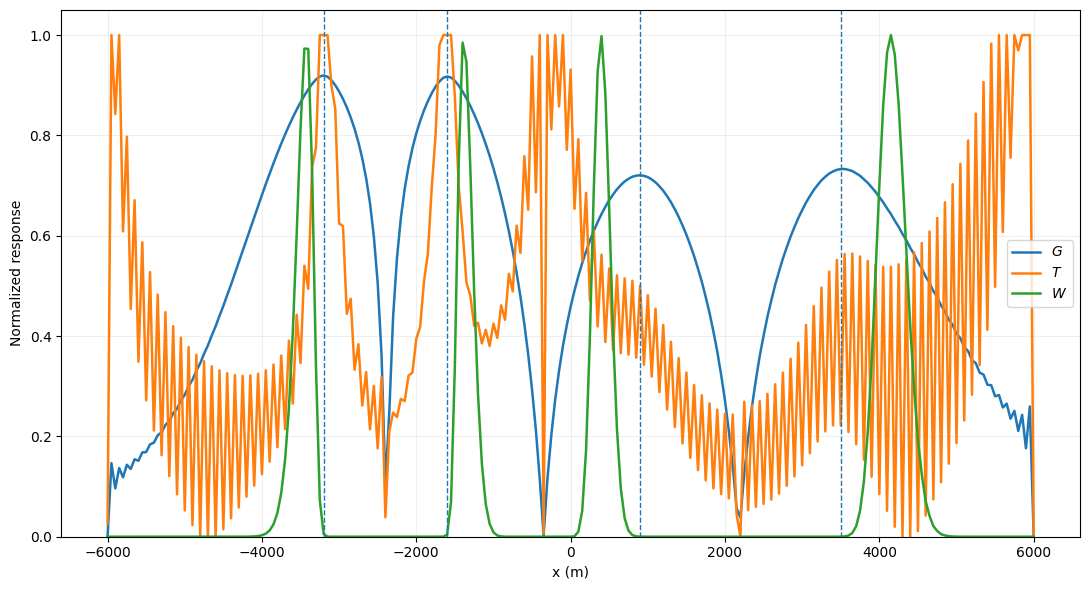

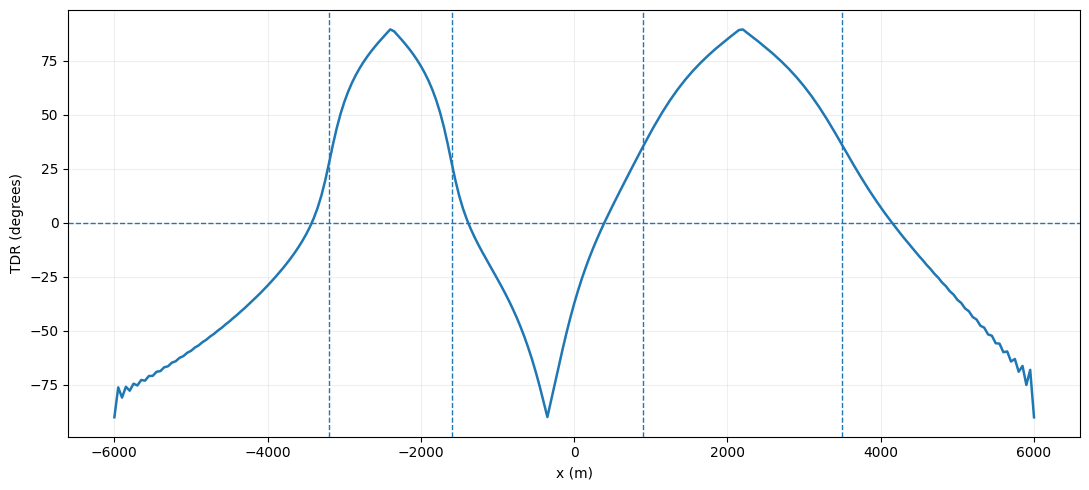

In [53]:
# Profiles of the individual V2 components
tdr_profile = tdr2[row2, :]
G_profile = G2_final[row2, :]
T_profile = T2[row2, :]
W_profile = W2[row2, :]

plt.figure(figsize=(11, 6))
plt.plot(x_profile2, G_profile, linewidth=1.8, label=r"$G$")
plt.plot(x_profile2, T_profile, linewidth=1.8, label=r"$T$")
plt.plot(x_profile2, W_profile, linewidth=1.8, label=r"$W$")

for edge in true_edges:
    plt.axvline(edge, linestyle="--", linewidth=1.0)

plt.xlabel("x (m)")
plt.ylabel("Normalized response")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
plt.plot(x_profile2, np.rad2deg(tdr_profile), linewidth=1.8)
plt.axhline(0.0, linestyle="--", linewidth=1.0)

for edge in true_edges:
    plt.axvline(edge, linestyle="--", linewidth=1.0)

plt.xlabel("x (m)")
plt.ylabel("TDR (degrees)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [54]:
# Zero crossings of the TDR central profile
def zero_crossings(xp, values):
    signs = np.sign(values)
    idx = np.where(np.diff(signs) != 0)[0]
    zeros = []

    for i in idx:
        x1, x2_ = xp[i], xp[i + 1]
        y1, y2_ = values[i], values[i + 1]

        if y2_ != y1:
            xzero = x1 - y1 * (x2_ - x1) / (y2_ - y1)
            zeros.append(xzero)

    return np.array(zeros)

tdr_zeros = zero_crossings(x_profile2, tdr_profile)

print("TDR zero crossings (m):")
print(tdr_zeros)
print("\nTrue source edges (m):")
print(true_edges)

TDR zero crossings (m):
[-3425.14223402 -1382.78290838   392.99584099  4148.12909477]

True source edges (m):
[-3200. -1600.   900.  3500.]


In [55]:
# Distance between true edges and nearest TDR zero crossing
print("Edge      Nearest TDR zero      Error")

tdr_zero_errors = []

for edge in true_edges:
    nearest = tdr_zeros[np.argmin(np.abs(tdr_zeros - edge))]
    error = abs(nearest - edge)
    tdr_zero_errors.append(error)
    print(f"{edge:7.1f}    {nearest:12.1f}    {error:7.1f}")

print(f"\nMean TDR zero-crossing error = {np.mean(tdr_zero_errors):.2f} m")

Edge      Nearest TDR zero      Error
-3200.0         -3425.1      225.1
-1600.0         -1382.8      217.2
  900.0           393.0      507.0
 3500.0          4148.1      648.1

Mean TDR zero-crossing error = 399.37 m


In [56]:
def normalize01(data):
    data = np.asarray(data, dtype=float)
    dmin = np.nanmin(data)
    dmax = np.nanmax(data)
    return (data - dmin) / (dmax - dmin + 1e-12)

ablation = {
    "G": normalize01(G2_final),
    "T": normalize01(T2),
    "W": normalize01(W2),
    "GT": normalize01(G2_final * T2),
    "GW": normalize01(G2_final * W2),
    "TW": normalize01(T2 * W2),
    "GTW": normalize01(G2_final * T2 * W2)
}

In [57]:
# Robust ablation metrics
def ablation_metrics(response, mask_A, mask_B, background_mask):
    values_A = response[mask_A & np.isfinite(response)]
    values_B = response[mask_B & np.isfinite(response)]
    values_bg = response[background_mask & np.isfinite(response)]

    mean_A = np.mean(values_A)
    mean_B = np.mean(values_B)
    balance = min(mean_A, mean_B) / (max(mean_A, mean_B) + 1e-12)
    bg95 = np.percentile(values_bg, 95)

    return mean_A, mean_B, balance, bg95

print(f"{'Term':<6} {'Edge A':>10} {'Edge B':>10} {'Balance':>10} {'BG Q95':>10} {'MAE':>10}")
print("-" * 62)

ablation_results = {}

for name, response in ablation.items():
    mean_A, mean_B, balance, bg95 = ablation_metrics(response, edge_A, edge_B, background2)
    detected, errors = edge_localization_errors(x_profile2, response[row2, :], true_edges, search_halfwidth)
    mae = np.mean(errors)

    ablation_results[name] = {
        "A": mean_A,
        "B": mean_B,
        "balance": balance,
        "bg95": bg95,
        "mae": mae
    }

    print(f"{name:<6} {mean_A:>10.3f} {mean_B:>10.3f} {balance:>10.3f} {bg95:>10.3f} {mae:>10.2f}")

Term       Edge A     Edge B    Balance     BG Q95        MAE
--------------------------------------------------------------
G           0.988      0.782      0.791      0.279      12.50
T           0.938      0.384      0.410      0.910     237.50
W           0.143      0.020      0.141      0.000     400.00
GT          0.927      0.300      0.324      0.171     187.50
GW          0.146      0.016      0.109      0.000     387.50
TW          0.164      0.010      0.064      0.000     375.00
GTW         0.168      0.008      0.049      0.000     375.00


In [58]:
# Detected edge positions for every ablation term
print(f"{'Term':<6} {'A-left':>10} {'A-right':>10} {'B-left':>10} {'B-right':>10}")
print("-" * 52)

for name, response in ablation.items():
    detected, errors = edge_localization_errors(x_profile2, response[row2, :], true_edges, search_halfwidth)
    print(f"{name:<6} {detected[0]:>10.0f} {detected[1]:>10.0f} {detected[2]:>10.0f} {detected[3]:>10.0f}")

Term       A-left    A-right     B-left    B-right
----------------------------------------------------
G           -3200      -1600        900       3550
T           -3250      -1650        200       3650
W           -3450      -1400        400       4150
GT          -3200      -1600        200       3550
GW          -3400      -1400        400       4150
TW          -3350      -1400        400       4150
GTW         -3350      -1400        400       4150


In [59]:
# Zero crossings of the TDR central profile
def zero_crossings(xp, values):
    signs = np.sign(values)
    idx = np.where(np.diff(signs) != 0)[0]
    zeros = []

    for i in idx:
        x1, x2_ = xp[i], xp[i + 1]
        y1, y2_ = values[i], values[i + 1]
        if y2_ != y1:
            zeros.append(x1 - y1 * (x2_ - x1) / (y2_ - y1))

    return np.array(zeros)

tdr_profile = tdr2[row2, :]
tdr_zeros = zero_crossings(x_profile2, tdr_profile)

print("TDR zero crossings (m):")
print(np.round(tdr_zeros, 1))

print("\nTrue edges and nearest TDR zero:")
tdr_zero_errors = []

for edge in true_edges:
    nearest = tdr_zeros[np.argmin(np.abs(tdr_zeros - edge))]
    error = abs(nearest - edge)
    tdr_zero_errors.append(error)
    print(f"Edge = {edge:7.1f} m | Zero = {nearest:7.1f} m | Error = {error:6.1f} m")

print(f"\nMean TDR zero-crossing error = {np.mean(tdr_zero_errors):.2f} m")

TDR zero crossings (m):
[-3425.1 -1382.8   393.   4148.1]

True edges and nearest TDR zero:
Edge = -3200.0 m | Zero = -3425.1 m | Error =  225.1 m
Edge = -1600.0 m | Zero = -1382.8 m | Error =  217.2 m
Edge =   900.0 m | Zero =   393.0 m | Error =  507.0 m
Edge =  3500.0 m | Zero =  4148.1 m | Error =  648.1 m

Mean TDR zero-crossing error = 399.37 m


In [60]:
# Minimal ablation study
def normalize01(data):
    dmin = np.nanmin(data)
    dmax = np.nanmax(data)
    return (data - dmin) / (dmax - dmin + 1e-12)

ablation = {
    "G": normalize01(G2_final),
    "GT": normalize01(G2_final * T2),
    "GW": normalize01(G2_final * W2),
    "GTW": normalize01(G2_final * T2 * W2)
}

print(f"{'Term':<6} {'Balance':>10} {'MAE (m)':>10}")
print("-" * 30)

for name, response in ablation.items():
    metrics = two_source_metrics(response, edge_A, edge_B, background2)
    detected, errors = edge_localization_errors(
        x_profile2,
        response[row2, :],
        true_edges,
        search_halfwidth
    )

    print(f"{name:<6} {metrics['balance']:>10.3f} {np.mean(errors):>10.2f}")

Term      Balance    MAE (m)
------------------------------
G           0.791      12.50
GT          0.324     187.50
GW          0.109     387.50
GTW         0.049     375.00


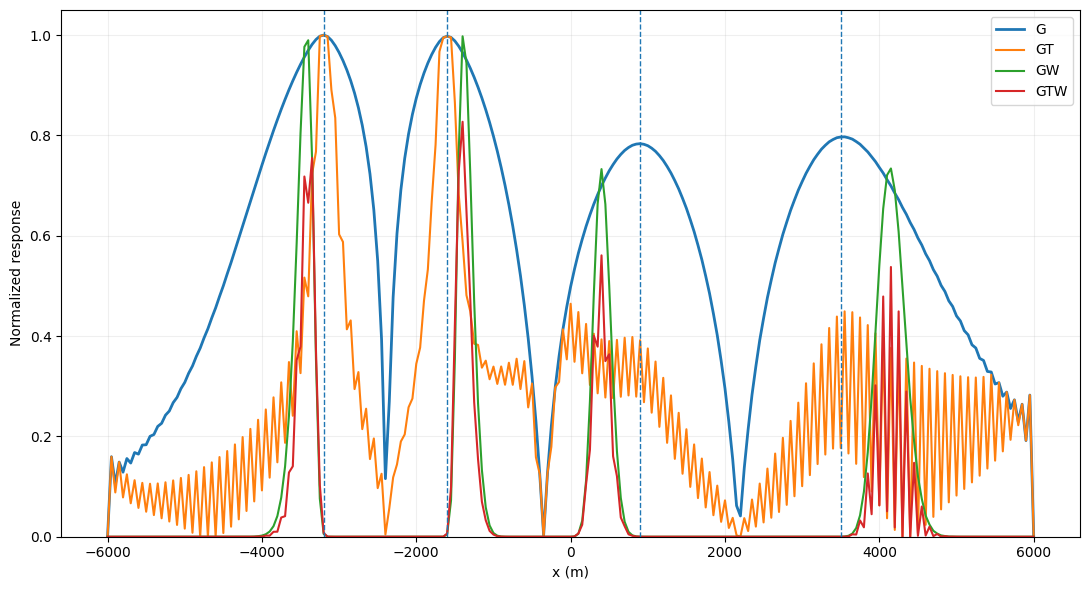

In [61]:
plt.figure(figsize=(11, 6))

plt.plot(x_profile2, ablation["G"][row2, :], linewidth=2.0, label="G")
plt.plot(x_profile2, ablation["GT"][row2, :], linewidth=1.5, label="GT")
plt.plot(x_profile2, ablation["GW"][row2, :], linewidth=1.5, label="GW")
plt.plot(x_profile2, ablation["GTW"][row2, :], linewidth=1.5, label="GTW")

for edge in true_edges:
    plt.axvline(edge, linestyle="--", linewidth=1.0)

plt.xlabel("x (m)")
plt.ylabel("Normalized response")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [62]:
# Bounded tilt modulation
CGT_bounded = G2_final * (1.0 + T2) / 2.0

responses_new = {
    "G": G2_final,
    "Old GTW": ablation["GTW"],
    "Bounded CGT": CGT_bounded
}

print(f"{'Term':<14} {'Balance':>10} {'MAE (m)':>10}")
print("-" * 36)

for name, response in responses_new.items():
    metrics = two_source_metrics(response, edge_A, edge_B, background2)
    detected, errors = edge_localization_errors(x_profile2, response[row2, :], true_edges, search_halfwidth)
    print(f"{name:<14} {metrics['balance']:>10.3f} {np.mean(errors):>10.2f}")

Term              Balance    MAE (m)
------------------------------------
G                   0.791      12.50
Old GTW             0.049     375.00
Bounded CGT         0.565      37.50


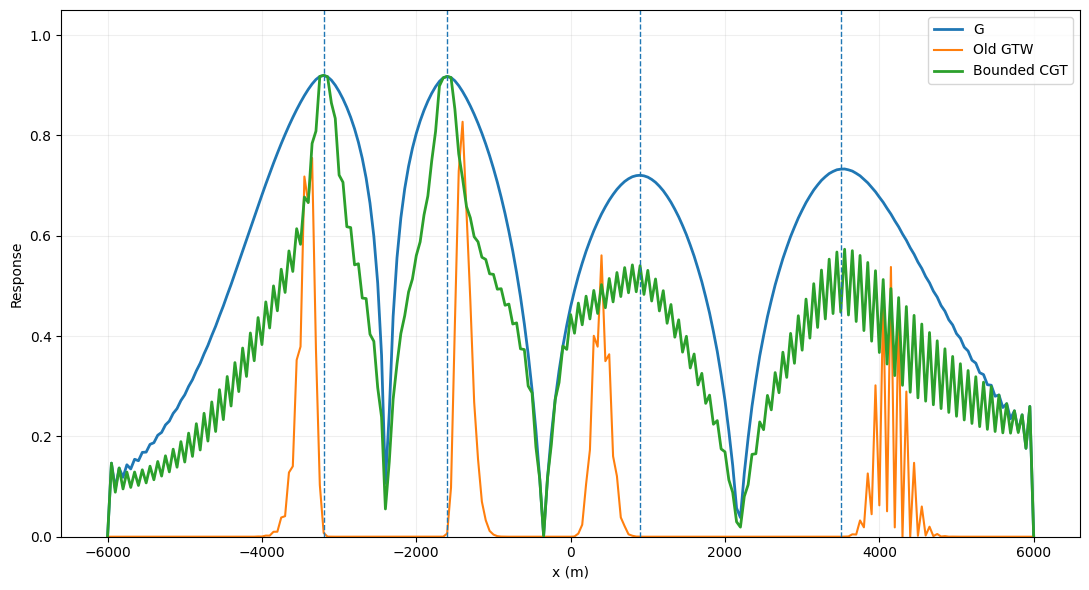

In [63]:
plt.figure(figsize=(11, 6))

plt.plot(x_profile2, G2_final[row2, :], linewidth=2.0, label="G")
plt.plot(x_profile2, ablation["GTW"][row2, :], linewidth=1.5, label="Old GTW")
plt.plot(x_profile2, CGT_bounded[row2, :], linewidth=2.0, label="Bounded CGT")

for edge in true_edges:
    plt.axvline(edge, linestyle="--", linewidth=1.0)

plt.xlabel("x (m)")
plt.ylabel("Response")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [64]:
# Sensitivity of the tilt-enhancement weight
gamma_values = [0.0, 0.10, 0.25, 0.50, 1.00]

print(f"{'gamma':>7} {'Balance':>10} {'MAE (m)':>10}")
print("-" * 31)

gamma_results = {}

for gamma in gamma_values:
    response = G2_final * (1.0 + gamma * T2)
    response = response / (np.nanmax(response) + 1e-12)

    metrics = two_source_metrics(response, edge_A, edge_B, background2)
    detected, errors = edge_localization_errors(
        x_profile2, response[row2, :], true_edges, search_halfwidth
    )

    gamma_results[gamma] = response
    print(f"{gamma:>7.2f} {metrics['balance']:>10.3f} {np.mean(errors):>10.2f}")

  gamma    Balance    MAE (m)
-------------------------------
   0.00      0.791      12.50
   0.10      0.751      12.50
   0.25      0.703      12.50
   0.50      0.642      12.50
   1.00      0.565      37.50


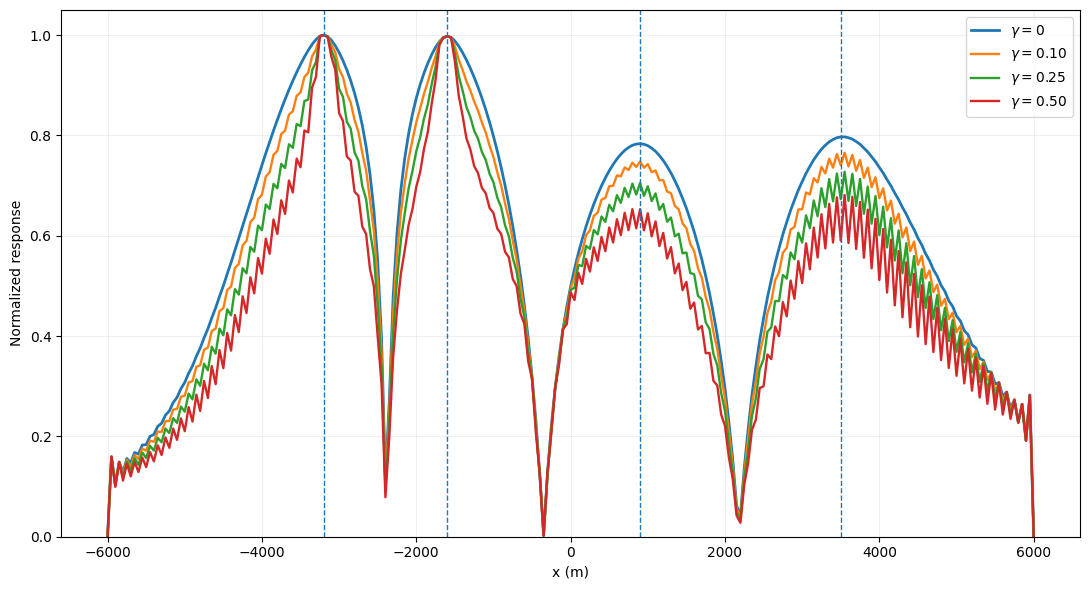

In [65]:
plt.figure(figsize=(11, 6))

plt.plot(x_profile2, gamma_results[0.0][row2, :], linewidth=2.0, label=r"$\gamma=0$")
plt.plot(x_profile2, gamma_results[0.10][row2, :], linewidth=1.7, label=r"$\gamma=0.10$")
plt.plot(x_profile2, gamma_results[0.25][row2, :], linewidth=1.7, label=r"$\gamma=0.25$")
plt.plot(x_profile2, gamma_results[0.50][row2, :], linewidth=1.7, label=r"$\gamma=0.50$")

for edge in true_edges:
    plt.axvline(edge, linestyle="--", linewidth=1.0)

plt.xlabel("x (m)")
plt.ylabel("Normalized response")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Teste 2 — Acoplamento Aditivo Normalizado entre Gradiente Horizontal e Tilt

## 1. Motivação

No teste anterior, foi investigada uma formulação multiplicativa para combinar a informação fornecida pelo gradiente horizontal com aquela fornecida pelo Tilt. A expressão testada foi

$$
CGT_h = G_h(1+\gamma T_h),
$$

em que:

- $G_h$ representa o gradiente horizontal;
- $T_h$ representa a contribuição associada ao Tilt;
- $\gamma$ é um parâmetro de ponderação que controla a influência do termo Tilt.

Os resultados mostraram que valores pequenos de $\gamma$ preservaram satisfatoriamente a localização das bordas. Entretanto, o aumento de $\gamma$ produziu uma redução progressiva do índice de balanceamento das amplitudes.

Para $\gamma=0$, correspondente ao gradiente horizontal sem contribuição do Tilt, foram obtidos:

$$
Balance = 0.791
$$

e

$$
MAE = 12.50\ {\rm m}.
$$

À medida que $\gamma$ aumentou, o valor de `Balance` diminuiu:

| $\gamma$ | Balance | MAE (m) |
|---:|---:|---:|
| 0.00 | 0.791 | 12.50 |
| 0.10 | 0.751 | 12.50 |
| 0.25 | 0.703 | 12.50 |
| 0.50 | 0.642 | 12.50 |
| 1.00 | 0.565 | 37.50 |

Portanto, embora a localização das bordas tenha permanecido praticamente inalterada para valores moderados de $\gamma$, a formulação multiplicativa não produziu melhoria no balanceamento das respostas.

Além disso, valores elevados de $\gamma$ introduziram oscilações progressivamente mais pronunciadas na curva filtrada.

Esse comportamento indica que a multiplicação

$$
G_h(1+\gamma T_h)
$$

faz com que a contribuição do Tilt permaneça fortemente condicionada à amplitude original de $G_h$. Em outras palavras, regiões que já apresentam respostas fortes no gradiente continuam sendo privilegiadas.

Por esse motivo, o próximo experimento considera uma formulação na qual as duas componentes participam de maneira independente e normalizada.

---

## 2. Objetivo do Teste 2

O objetivo deste teste é avaliar se uma combinação **aditiva e ponderada** entre o gradiente horizontal e o Tilt pode melhorar o equilíbrio entre respostas associadas a diferentes bordas sem comprometer sua localização espacial.

A hipótese investigada é que, após a normalização independente das duas componentes, o Tilt poderá contribuir efetivamente para reforçar respostas relativamente fracas, em vez de apenas modificar amplitudes previamente determinadas pelo gradiente horizontal.

Busca-se, portanto, uma formulação capaz de simultaneamente:

1. preservar a posição das bordas;
2. aumentar o balanceamento entre respostas fortes e fracas;
3. evitar oscilações excessivas;
4. preservar a interpretação física do operador;
5. fornecer uma base adequada para a futura extensão multiescala do método.

---

# 3. Gradiente Horizontal

Considere um campo potencial $F(x,z)$ ao longo de um perfil.

No caso bidimensional utilizado neste teste, o gradiente horizontal pode ser representado por

$$
G_h(x)
=
\left|
\frac{\partial F}{\partial x}
\right|.
$$

De forma mais geral, para dados bidimensionais distribuídos nas direções $x$ e $y$, tem-se

$$
G_h(x,y)
=
\sqrt{
\left(
\frac{\partial F}{\partial x}
\right)^2
+
\left(
\frac{\partial F}{\partial y}
\right)^2
}.
$$

O gradiente horizontal é amplamente empregado na detecção de contatos e limites laterais de fontes.

Entretanto, sua amplitude depende fortemente da intensidade e da profundidade da fonte. Como consequência, estruturas mais rasas ou mais intensas podem dominar a resposta, dificultando a identificação equilibrada de fontes mais profundas ou menos intensas.

---

# 4. Tilt

O Tilt é construído a partir da relação entre derivadas verticais e horizontais do campo.

Uma forma clássica é

$$
T(x)
=
\arctan
\left(
\frac{
\dfrac{\partial F}{\partial z}
}{
G_h(x)
}
\right).
$$

Para o caso bidimensional geral,

$$
T(x,y)
=
\arctan
\left[
\frac{
\dfrac{\partial F}{\partial z}
}{
\sqrt{
\left(
\dfrac{\partial F}{\partial x}
\right)^2
+
\left(
\dfrac{\partial F}{\partial y}
\right)^2
}
}
\right].
$$

Uma característica importante do Tilt é sua normalização implícita pela magnitude do gradiente horizontal.

Isso tende a reduzir parcialmente a dependência direta da resposta em relação à amplitude absoluta da anomalia, tornando o operador particularmente interessante para a identificação de estruturas com diferentes intensidades e profundidades.

---

# 5. Necessidade de normalização

Antes de realizar uma combinação aditiva, $G_h$ e $T_h$ devem ser colocados em escalas compatíveis.

Sem essa normalização, uma das duas componentes poderia dominar numericamente a combinação simplesmente por apresentar maior amplitude.

Define-se inicialmente o gradiente horizontal normalizado como

$$
\widehat{G}_h(x)
=
\frac{
G_h(x)
}{
\max\limits_x G_h(x)
}.
$$

Assim,

$$
0
\leq
\widehat{G}_h
\leq
1.
$$

De maneira análoga, será construída uma resposta positiva associada ao Tilt, denotada por

$$
\widehat{T}_h(x),
$$

também normalizada de forma que

$$
0
\leq
\widehat{T}_h
\leq
1.
$$

A definição computacional exata de $\widehat{T}_h$ será mantida consistente com o operador Tilt utilizado no experimento anterior.

---

# 6. Nova formulação proposta

O segundo teste considera a combinação

$$
\boxed{
CGT_h(x;\gamma)
=
(1-\gamma)\widehat{G}_h(x)
+
\gamma\widehat{T}_h(x)
}
$$

com

$$
0
\leq
\gamma
\leq
1.
$$

O parâmetro $\gamma$ controla diretamente a contribuição relativa das duas componentes.

A parcela

$$
(1-\gamma)\widehat{G}_h
$$

representa a contribuição do gradiente horizontal, enquanto

$$
\gamma\widehat{T}_h
$$

representa a contribuição do Tilt.

Diferentemente da formulação multiplicativa anterior, os dois operadores agora participam independentemente da resposta final.

---

# 7. Interpretação de $\gamma$

A formulação possui dois casos extremos particularmente importantes.

Para

$$
\gamma=0,
$$

obtém-se

$$
CGT_h
=
\widehat{G}_h.
$$

Portanto, o resultado corresponde exclusivamente ao gradiente horizontal normalizado.

Esse caso constitui a referência ou `baseline` do experimento.

No outro extremo, para

$$
\gamma=1,
$$

tem-se

$$
CGT_h
=
\widehat{T}_h,
$$

correspondendo exclusivamente à componente Tilt.

Para valores intermediários,

$$
0<\gamma<1,
$$

o operador representa uma combinação ponderada das duas informações.

Por exemplo, para

$$
\gamma=0.25,
$$

tem-se

$$
CGT_h
=
0.75\widehat{G}_h
+
0.25\widehat{T}_h.
$$

Já para

$$
\gamma=0.50,
$$

as duas componentes recebem o mesmo peso:

$$
CGT_h
=
0.50\widehat{G}_h
+
0.50\widehat{T}_h.
$$

---

# 8. Valores de $\gamma$ investigados

Nesta etapa será realizada uma varredura inicial utilizando

$$
\gamma
=
0.00,\,
0.10,\,
0.25,\,
0.50,\,
0.75,\,
1.00.
$$

Essa escolha permite avaliar desde o gradiente horizontal puro até o Tilt puro, incluindo diferentes níveis intermediários de acoplamento.

Caso seja identificada uma região promissora, uma busca mais refinada poderá ser realizada posteriormente.

Por exemplo, se os melhores resultados ocorrerem aproximadamente entre

$$
0.20
\leq
\gamma
\leq
0.40,
$$

poderá ser utilizada uma busca fina com incremento

$$
\Delta\gamma=0.02.
$$

---

# 9. Controle experimental

Para permitir uma comparação rigorosa com o experimento anterior, nenhuma característica do modelo sintético será alterada.

Serão mantidos:

- os mesmos prismas;
- as mesmas propriedades físicas;
- as mesmas profundidades;
- as mesmas dimensões;
- a mesma malha;
- os mesmos pontos de observação;
- as mesmas posições verdadeiras das bordas;
- o mesmo procedimento de cálculo das derivadas;
- os mesmos critérios de detecção de picos.

Dessa maneira, qualquer diferença observada poderá ser atribuída exclusivamente à nova forma de combinar o gradiente horizontal e o Tilt.

---

# 10. Métrica de localização das bordas

A primeira métrica utilizada continuará sendo o erro absoluto médio, `MAE`.

Sejam

$$
x_i^{\rm true}
$$

as posições verdadeiras das bordas e

$$
x_i^{\rm det}
$$

as respectivas posições detectadas pelo filtro.

O erro absoluto médio é definido como

$$
MAE
=
\frac{1}{N}
\sum_{i=1}^{N}
\left|
x_i^{\rm det}
-
x_i^{\rm true}
\right|.
$$

Quanto menor o valor do `MAE`, maior a precisão espacial da detecção.

No teste anterior, o valor de referência foi

$$
MAE_{\gamma=0}
=
12.50\ {\rm m}.
$$

Idealmente, a nova formulação deverá manter

$$
MAE
\approx
12.50\ {\rm m}
$$

ou apresentar valor inferior.

---

# 11. Métrica de balanceamento

Além da localização, deseja-se avaliar se o operador produz respostas de amplitude comparável para diferentes bordas.

O índice `Balance` utilizado no teste anterior continuará sendo empregado.

Seu objetivo é quantificar o equilíbrio entre as amplitudes das respostas detectadas.

Valores mais próximos de

$$
1
$$

indicam respostas mais equilibradas.

No experimento anterior, a referência correspondente ao gradiente horizontal foi

$$
Balance_{\gamma=0}
=
0.791.
$$

Portanto, uma das metas da nova formulação é obter

$$
Balance
>
0.791
$$

sem aumento significativo do erro de localização.

---

# 12. Métrica de rugosidade

O experimento multiplicativo mostrou que o aumento da contribuição do Tilt pode gerar oscilações locais na resposta.

Consequentemente, neste teste será incorporada uma terceira métrica quantitativa: a rugosidade da curva.

Para uma resposta discreta

$$
f_i = CGT_h(x_i),
$$

define-se o índice de rugosidade como

$$
R
=
\frac{1}{N-2}
\sum_{i=2}^{N-1}
\left|
f_{i+1}
-
2f_i
+
f_{i-1}
\right|.
$$

A expressão corresponde à média do módulo da segunda diferença discreta da curva.

Valores pequenos de

$$
R
$$

indicam uma resposta relativamente suave.

Valores elevados indicam maior oscilação ou serrilhamento.

Assim, deseja-se simultaneamente:

$$
Balance \rightarrow \text{máximo},
$$

$$
MAE \rightarrow \text{mínimo},
$$

e

$$
R \rightarrow \text{mínimo}.
$$

---

# 13. Problema multicritério

A escolha do melhor valor de $\gamma$ não deve ser baseada exclusivamente na maior amplitude dos picos.

O problema envolve três aspectos distintos:

### Localização

$$
MAE(\gamma)
$$

deve permanecer pequeno.

### Balanceamento

$$
Balance(\gamma)
$$

deve ser maximizado.

### Estabilidade

$$
R(\gamma)
$$

deve permanecer baixo.

Portanto, um valor de $\gamma$ somente será considerado vantajoso caso apresente uma melhoria global no comportamento do operador.

---

# 14. Critério inicial de sucesso

O caso

$$
\gamma=0
$$

será utilizado como referência.

Os valores conhecidos são

$$
Balance_0=0.791
$$

e

$$
MAE_0=12.50\ {\rm m}.
$$

A nova formulação será considerada promissora se existir pelo menos um valor

$$
\gamma>0
$$

tal que

$$
Balance(\gamma)
>
Balance_0
$$

e simultaneamente

$$
MAE(\gamma)
\leq
MAE_0
$$

ou permaneça suficientemente próximo desse valor.

Também será necessário verificar se

$$
R(\gamma)
$$

não apresenta crescimento excessivo.

Em termos conceituais, procura-se uma solução que produza

$$
\boxed{
\text{melhor balanceamento}
+
\text{boa localização}
+
\text{baixa rugosidade}
}
$$

---

# 15. Resultados que deverão ser gerados

Para cada valor de $\gamma$, serão calculados:

1. a resposta $CGT_h$;
2. as posições das bordas detectadas;
3. as amplitudes dos picos associados às bordas;
4. o índice `Balance`;
5. o `MAE`;
6. o índice de rugosidade $R$.

Os resultados serão organizados em uma tabela no formato

| $\gamma$ | Balance | MAE (m) | Roughness |
|---:|---:|---:|---:|
| 0.00 | ... | ... | ... |
| 0.10 | ... | ... | ... |
| 0.25 | ... | ... | ... |
| 0.50 | ... | ... | ... |
| 0.75 | ... | ... | ... |
| 1.00 | ... | ... | ... |

Também será construído um gráfico contendo todas as respostas normalizadas, juntamente com linhas verticais indicando as posições verdadeiras das bordas.

---

# 16. Hipóteses possíveis

Ao final deste teste, três comportamentos principais podem ocorrer.

## Hipótese A — melhora simultânea

Se algum valor

$$
\gamma>0
$$

produzir

$$
Balance(\gamma)>Balance(0)
$$

mantendo

$$
MAE(\gamma)\approx MAE(0)
$$

e baixa rugosidade, então haverá evidência de que a combinação aditiva fornece informação adicional útil.

Nesse caso, o parâmetro $\gamma$ será refinado em uma busca posterior.

---

## Hipótese B — melhora do balanceamento com pequena perda espacial

Também pode ocorrer que

$$
Balance(\gamma)>Balance(0),
$$

mas acompanhado por um pequeno aumento de

$$
MAE.
$$

Nesse caso será necessário avaliar quantitativamente o compromisso entre balanceamento e localização.

Uma pequena perda espacial poderá ser aceitável caso o ganho de balanceamento seja suficientemente significativo.

---

## Hipótese C — ausência de ganho

Se nenhum valor de $\gamma$ produzir melhoria em relação ao gradiente horizontal puro, então a combinação aditiva simples também deverá ser rejeitada.

Nesse cenário, novas formas funcionais de integração entre $G_h$ e $T_h$ deverão ser investigadas antes da formulação multiescala.

---

# 17. Por que este teste deve preceder a abordagem multiescala?

O objetivo final é construir um operador MS-CGTP, no qual `MS` representa uma abordagem multiescala.

Entretanto, não é conveniente introduzir a dimensão de escala antes de compreender o comportamento fundamental do acoplamento entre os operadores.

Caso fossem modificados simultaneamente:

- o tipo de combinação;
- o parâmetro $\gamma$;
- a escala;
- o número de continuações;
- a ponderação entre escalas;

seria difícil identificar qual componente efetivamente produziu uma eventual melhoria.

Por esse motivo, o desenvolvimento seguirá uma estratégia incremental e controlada.

---

# 18. Sequência metodológica planejada

O desenvolvimento será realizado aproximadamente na seguinte ordem:

### Teste 1 — combinação multiplicativa

$$
CGT_h
=
G_h(1+\gamma T_h)
$$

Status: concluído.

Resultado principal: preservação da localização para pequenos valores de $\gamma$, mas redução do balanceamento com o aumento da contribuição Tilt.

---

### Teste 2 — combinação aditiva normalizada

$$
CGT_h
=
(1-\gamma)\widehat{G}_h
+
\gamma\widehat{T}_h
$$

Status: próximo experimento.

Objetivo: verificar se a independência entre as duas componentes permite melhorar o balanceamento.

---

### Teste 3 — refinamento de $\gamma$

Caso o Teste 2 revele uma região favorável, será realizada uma busca mais fina do parâmetro.

---

### Teste 4 — robustez ao ruído

Após a definição da formulação básica, será introduzido ruído sintético controlado.

O objetivo será avaliar a estabilidade do operador diante de condições mais próximas de dados observacionais reais.

---

### Teste 5 — fontes em diferentes profundidades

Serão utilizadas estruturas com diferentes profundidades e, quando necessário, diferentes propriedades físicas.

Este teste será particularmente importante para avaliar a capacidade de balanceamento do filtro.

---

### Teste 6 — extensão multiescala

Somente depois de validada a combinação básica será introduzida a dimensão multiescala.

O objetivo será investigar como a resposta do operador varia com a profundidade de continuação e como diferentes escalas podem ser combinadas em uma resposta única.

---

# 19. Objetivo final

A meta não é simplesmente construir um filtro que produza picos visualmente mais fortes.

O objetivo é desenvolver um operador que apresente vantagens quantitativamente demonstráveis em relação aos filtros utilizados como referência.

O desenvolvimento deve, portanto, ser sustentado por critérios objetivos de:

$$
\boxed{
\text{localização}
}
$$

$$
\boxed{
\text{balanceamento}
}
$$

$$
\boxed{
\text{estabilidade}
}
$$

e, posteriormente,

$$
\boxed{
\text{robustez multiescala}.
}
$$

O Teste 2 constitui, portanto, a próxima etapa de validação da formulação fundamental do futuro MS-CGTP.

In [72]:
# ============================================================
# TESTE 2 — ACOPLAMENTO ADITIVO NORMALIZADO G–T
# ============================================================

gammas = [0.00, 0.10, 0.25, 0.50, 0.75, 1.00]
true_edges = np.array([-3200., -1600., 900., 3500.])
search_halfwidth = 700.0
tol_edge = 100.0

def normalize_response(a):
    a = np.asarray(a, dtype=float)
    amin, amax = np.nanmin(a), np.nanmax(a)
    return (a - amin)/(amax - amin + 1e-12)

# Componentes diferenciais do modelo de dois prismas
components_add = filtering.my_cgtp_grid(
    x2, y2, gz2,
    pad_factor=0.5,
    pad_mode="reflect",
    taper=True,
    alpha=1.0,
    beta=1.0,
    sigma_tilt=np.deg2rad(12.0),
    return_components=True
)

# G: gradiente saturado proposto, usando Q75
hgm_add = components_add["hgm"]
lambda_g_add = np.nanpercentile(hgm_add, 75)
G = hgm_add/(hgm_add + lambda_g_add + 1e-12)

# T: gradiente horizontal do Tilt normalizado
T = components_add["thdr_tdr_normalized"]

G = normalize_response(G)
T = normalize_response(T)

# Máscaras das bordas verdadeiras dos dois prismas
def rectangular_edge_mask_local(x, y, prism, tolerance=100.0):
    xi, xf, yi, yf = prism[:4]
    vertical = (((np.abs(x-xi) <= tolerance) | (np.abs(x-xf) <= tolerance)) &
                (y >= yi-tolerance) & (y <= yf+tolerance))
    horizontal = (((np.abs(y-yi) <= tolerance) | (np.abs(y-yf) <= tolerance)) &
                  (x >= xi-tolerance) & (x <= xf+tolerance))
    return vertical | horizontal

mask_A_add = rectangular_edge_mask_local(x2, y2, prism_A, tol_edge)
mask_B_add = rectangular_edge_mask_local(x2, y2, prism_B, tol_edge)

# Perfil central
row_add = np.argmin(np.abs(y2[:, 0]))
x_profile_add = x2[row_add, :]

def localization_mae(xp, profile, edges, halfwidth):
    errors = []
    for edge in edges:
        mask = np.abs(xp-edge) <= halfwidth
        x_local = xp[mask]
        p_local = profile[mask]
        detected = x_local[np.nanargmax(p_local)]
        errors.append(abs(detected-edge))
    return np.mean(errors)

def profile_roughness(profile):
    p = normalize_response(profile)
    return np.nanmean(np.abs(np.diff(p, n=2)))

print(f"{'gamma':>7} {'Balance':>11} {'MAE (m)':>11} {'Roughness':>12}")
print("-"*45)

results_add = {}

for gamma in gammas:
    CGT = (1.0-gamma)*G + gamma*T
    CGT = normalize_response(CGT)

    mean_A = np.nanmean(CGT[mask_A_add])
    mean_B = np.nanmean(CGT[mask_B_add])
    balance = min(mean_A, mean_B)/(max(mean_A, mean_B) + 1e-12)

    profile = CGT[row_add, :]
    mae = localization_mae(
        x_profile_add, profile,
        true_edges, search_halfwidth
    )
    roughness = profile_roughness(profile)

    results_add[gamma] = {
        "response": CGT,
        "balance": balance,
        "mae": mae,
        "roughness": roughness
    }

    print(f"{gamma:7.2f} {balance:11.3f} {mae:11.2f} {roughness:12.5f}")

  gamma     Balance     MAE (m)    Roughness
---------------------------------------------
   0.00       0.791       12.50      0.01570
   0.10       0.755       12.50      0.05995
   0.25       0.700       37.50      0.12937
   0.50       0.606      187.50      0.24590
   0.75       0.509      187.50      0.36271
   1.00       0.410      237.50      0.47892


In [73]:
# ============================================================
# TESTE MULTIESCALA E PERSISTÊNCIA
# ============================================================

scales = [0., 250., 500., 1000.]
q = 75
noise_level = 0.05
nreal = 20
eps = 1e-12

X = np.asarray(x2)
Y = np.asarray(y2)
F0 = np.asarray(gz2).reshape(X.shape)
ny, nx = F0.shape
dx = abs(X[0,1] - X[0,0])
dy = abs(Y[1,0] - Y[0,0])

def spectral_hgm(field, height):
    py, px = ny//4, nx//4
    fp = np.pad(field, ((py,py),(px,px)), mode="reflect")
    nyp, nxp = fp.shape
    kx = 2*np.pi*np.fft.fftfreq(nxp, d=dx)
    ky = 2*np.pi*np.fft.fftfreq(nyp, d=dy)
    KX, KY = np.meshgrid(kx, ky)
    K = np.sqrt(KX**2 + KY**2)
    F = np.fft.fft2(fp)
    U = np.exp(-K*height)
    fx = np.real(np.fft.ifft2(1j*KX*F*U))
    fy = np.real(np.fft.ifft2(1j*KY*F*U))
    hgm = np.sqrt(fx**2 + fy**2)
    return hgm[py:py+ny, px:px+nx]

def norm01(a):
    amin, amax = np.min(a), np.max(a)
    return (a-amin)/(amax-amin+eps)

def multiscale_responses(field):
    Gs = []
    for h in scales:
        H = spectral_hgm(field, h)
        lam = np.percentile(H, q)
        Gs.append(H/(H+lam+eps))
    Gs = np.asarray(Gs)
    G = norm01(Gs[0])
    Gms = norm01(np.mean(Gs, axis=0))
    meanG = np.mean(Gs, axis=0)
    P = np.clip(1 - np.std(Gs, axis=0)/(meanG+eps), 0, 1)
    Gmsp = norm01(Gms*P)
    return G, Gms, Gmsp

def edge_mask(prism, tol=100.):
    x1,x2p,y1,y2p = prism[:4]
    vertical = (((abs(X-x1)<=tol)|(abs(X-x2p)<=tol)) & (Y>=y1-tol) & (Y<=y2p+tol))
    horizontal = (((abs(Y-y1)<=tol)|(abs(Y-y2p)<=tol)) & (X>=x1-tol) & (X<=x2p+tol))
    return vertical | horizontal

maskA = edge_mask(prism_A)
maskB = edge_mask(prism_B)
true_edges = np.array([-3200., -1600., 900., 3500.])
row = np.argmin(abs(Y[:,0]))
xp = X[row,:]

def balance(response):
    a = np.mean(response[maskA])
    b = np.mean(response[maskB])
    return min(a,b)/(max(a,b)+eps)

def localization_mae(response, halfwidth=700.):
    profile = response[row,:]
    errors = []
    for xe in true_edges:
        m = abs(xp-xe) <= halfwidth
        xd = xp[m][np.argmax(profile[m])]
        errors.append(abs(xd-xe))
    return np.mean(errors)

G, Gms, Gmsp = multiscale_responses(F0)
responses = {"G":G, "G_MS":Gms, "G_MSP":Gmsp}

rng = np.random.default_rng(42)
noise_mae = {k:[] for k in responses}

for _ in range(nreal):
    Fn = F0 + rng.normal(0, noise_level*np.std(F0), F0.shape)
    Gn, Gmsn, Gmspn = multiscale_responses(Fn)
    for name,R in zip(noise_mae,[Gn,Gmsn,Gmspn]):
        noise_mae[name].append(localization_mae(R))

print(f"{'Method':<10} {'Balance':>10} {'MAE (m)':>10} {'MAE noise (m)':>20}")
print("-"*54)
for name,R in responses.items():
    vals = np.asarray(noise_mae[name])
    print(f"{name:<10} {balance(R):>10.3f} {localization_mae(R):>10.2f} {vals.mean():>9.2f} ± {vals.std():.2f}")

Method        Balance    MAE (m)        MAE noise (m)
------------------------------------------------------
G               0.788      25.00    177.50 ± 57.64
G_MS            0.781      25.00    107.50 ± 33.63
G_MSP           0.786     125.00    110.62 ± 41.51


## Synthetic Test 1 — Fault-controlled sedimentary basin

The first synthetic experiment represents a fault-controlled sedimentary basin composed of three adjacent structural compartments with different basement depths. The model contains an intermediate western depocenter, a central basement high, and a deeper eastern depocenter.

All compartments are assigned the same density contrast. Therefore, variations in the amplitudes of the gravity and edge-detector responses are controlled primarily by source geometry and depth rather than by lateral changes in density contrast.

The experiment compares:

- HGM — conventional horizontal gradient magnitude;
- QHGM — quantile-normalized horizontal gradient magnitude;
- MS-QHGM — multiscale quantile-normalized horizontal gradient magnitude.

For each upward-continuation height $h$, the horizontal gradient magnitude is

$$
H_h(x,y)=
\sqrt{
\left(\frac{\partial f_h}{\partial x}\right)^2+
\left(\frac{\partial f_h}{\partial y}\right)^2
}.
$$

The quantile-normalized response is defined as

$$
G_h(x,y)=
\frac{H_h(x,y)}
{H_h(x,y)+Q_{75}(H_h)}.
$$

The proposed multiscale response is

$$
MS\text{-}QHGM(x,y)
=
N\left[
\frac{1}{K}
\sum_{k=1}^{K}G_{h_k}(x,y)
\right].
$$

The continuation heights are defined relative to the grid spacing $\Delta$:

$$
h_k=
\{0,5\Delta,10\Delta,20\Delta\}.
$$

In addition to contour maps of the filter responses, two-dimensional edge-ridge maps are extracted from local maxima of each normalized response. The known structural boundaries of the synthetic model are plotted only as reference lines and are not used during edge extraction.

The quantitative evaluation considers the mean absolute localization error (`MAE`) and the response balance between structural boundaries located at different depths.es associated with structures at different depths.

In [76]:
xmin, xmax = -30000., 30000.
ymin, ymax = -20000., 20000.
dx = dy = 250.

xv = np.arange(xmin, xmax + dx, dx)
yv = np.arange(ymin, ymax + dy, dy)

X1, Y1 = np.meshgrid(xv, yv)
Z1 = np.zeros_like(X1)

rho = -0.25  # g/cm³

prisms1 = [
    [-22000., -8000., -10000., 10000., 500., 3500., rho],
    [ -8000.,  5000., -10000., 10000., 500., 1800., rho],
    [  5000., 22000., -10000., 10000., 500., 6000., rho]
]

gz1 = synthetic.my_forward_prisms_gz(
    X1.ravel(),
    Y1.ravel(),
    Z1.ravel(),
    prisms1
).reshape(X1.shape)

In [77]:
def spectral_hgm(data, dx, dy, height=0., pad_factor=0.5):
    ny, nx = data.shape
    py = int(ny * pad_factor)
    px = int(nx * pad_factor)

    data_pad = np.pad(
        data,
        ((py, py), (px, px)),
        mode="reflect")

    nyp, nxp = data_pad.shape
    kx = 2*np.pi*np.fft.fftfreq(nxp, d=dx)
    ky = 2*np.pi*np.fft.fftfreq(nyp, d=dy)
    KX, KY = np.meshgrid(kx, ky)
    K = np.sqrt(KX**2 + KY**2)
    F = np.fft.fft2(data_pad)
    Fh = F*np.exp(-height*K)
    fx = np.real(np.fft.ifft2(1j*KX*Fh))
    fy = np.real(np.fft.ifft2(1j*KY*Fh))
    H = np.sqrt(fx**2 + fy**2)

    return H[py:py+ny, px:px+nx]

def normalize01(a):
    amin = np.nanmin(a)
    amax = np.nanmax(a)
    return (a-amin)/(amax-amin+1e-15)

In [79]:
delta = max(dx, dy)

heights = np.array([
    0.,
    5.*delta,
    10.*delta,
    20.*delta
])

H_scales = []
G_scales = []

for h in heights:

    H = spectral_hgm(
        gz1,
        dx,
        dy,
        height=h,
        pad_factor=0.5
    )

    q75 = np.nanpercentile(H, 75)

    G = H/(H + q75 + 1e-15)

    H_scales.append(H)
    G_scales.append(G)

HGM1 = normalize01(H_scales[0])
QHGM1 = normalize01(G_scales[0])

MSQHGM1 = normalize01(
    np.mean(
        np.asarray(G_scales),
        axis=0
    )
)

methods1 = {
    "HGM": HGM1,
    "QHGM": QHGM1,
    "MS-QHGM": MSQHGM1
}

In [80]:
def detect_edge_ridges(response, percentile=85):

    R = normalize01(response)

    ridge_x = np.zeros_like(R, dtype=bool)
    ridge_y = np.zeros_like(R, dtype=bool)

    ridge_x[:,1:-1] = (
        (R[:,1:-1] >= R[:,:-2]) &
        (R[:,1:-1] >= R[:,2:])
    )

    ridge_y[1:-1,:] = (
        (R[1:-1,:] >= R[:-2,:]) &
        (R[1:-1,:] >= R[2:,:])
    )

    threshold = np.nanpercentile(
        R,
        percentile
    )

    ridges = (
        (ridge_x | ridge_y) &
        (R >= threshold)
    )

    border = 4

    ridges[:border,:] = False
    ridges[-border:,:] = False
    ridges[:,:border] = False
    ridges[:,-border:] = False

    return ridges

detected_edges1 = {}

for name, response in methods1.items():

    detected_edges1[name] = detect_edge_ridges(
        response,
        percentile=85)

In [81]:
row1 = np.argmin(np.abs(yv))

true_edges1 = np.array([
    -22000.,
     -8000.,
      5000.,
     22000.
])

search_halfwidth = 3000.

def structural_metrics(response):

    profile = response[row1,:]

    detected = []
    errors = []
    amplitudes = []

    for edge in true_edges1:

        mask = np.abs(xv-edge) <= search_halfwidth

        xx = xv[mask]
        pp = profile[mask]

        j = np.nanargmax(pp)

        detected.append(xx[j])
        errors.append(abs(xx[j]-edge))
        amplitudes.append(pp[j])

    detected = np.asarray(detected)
    errors = np.asarray(errors)
    amplitudes = np.asarray(amplitudes)

    balance = (
        np.nanmin(amplitudes) /
        (np.nanmax(amplitudes)+1e-15)
    )

    mae = np.nanmean(errors)

    return detected, errors, balance, mae

results1 = {}

print(
    f"{'Method':<12}"
    f"{'Balance':>12}"
    f"{'MAE (m)':>14}"
)

print("-"*38)

for name, response in methods1.items():

    detected, errors, balance, mae = structural_metrics(
        response
    )

    results1[name] = {
        "detected": detected,
        "errors": errors,
        "balance": balance,
        "mae": mae
    }

    print(
        f"{name:<12}"
        f"{balance:>12.3f}"
        f"{mae:>14.2f}")

Method           Balance       MAE (m)
--------------------------------------
HGM                0.244          0.00
QHGM               0.594          0.00
MS-QHGM            0.480          0.00


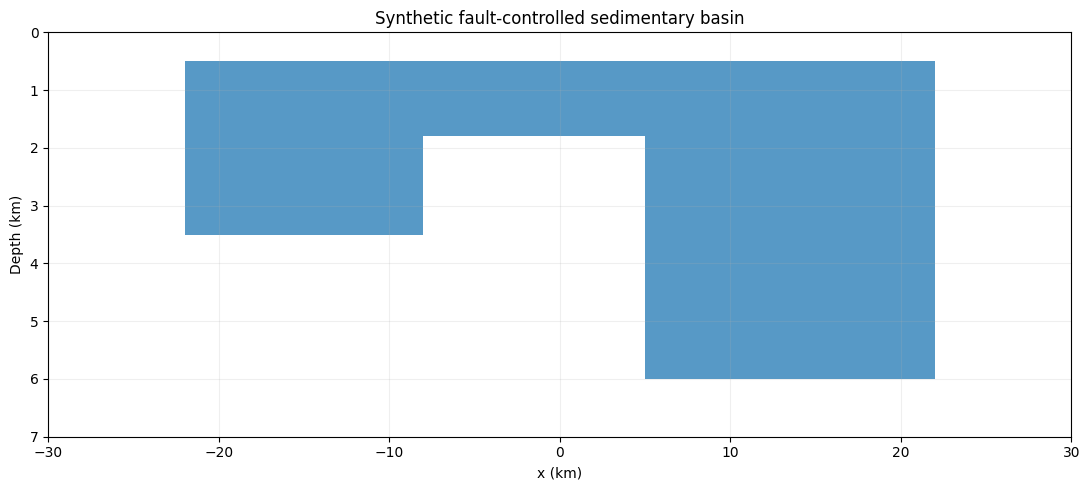

In [82]:
fig, ax = plt.subplots(figsize=(11,5))

for p in prisms1:

    xa, xb, ya, yb, top, bottom, density = p

    rect = Rectangle(
        (xa/1000., top/1000.),
        (xb-xa)/1000.,
        (bottom-top)/1000.,
        alpha=0.75
    )

    ax.add_patch(rect)

ax.set_xlim(
    xmin/1000.,
    xmax/1000.
)

ax.set_ylim(7.,0.)

ax.set_xlabel("x (km)")
ax.set_ylabel("Depth (km)")

ax.set_title(
    "Synthetic fault-controlled sedimentary basin"
)

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

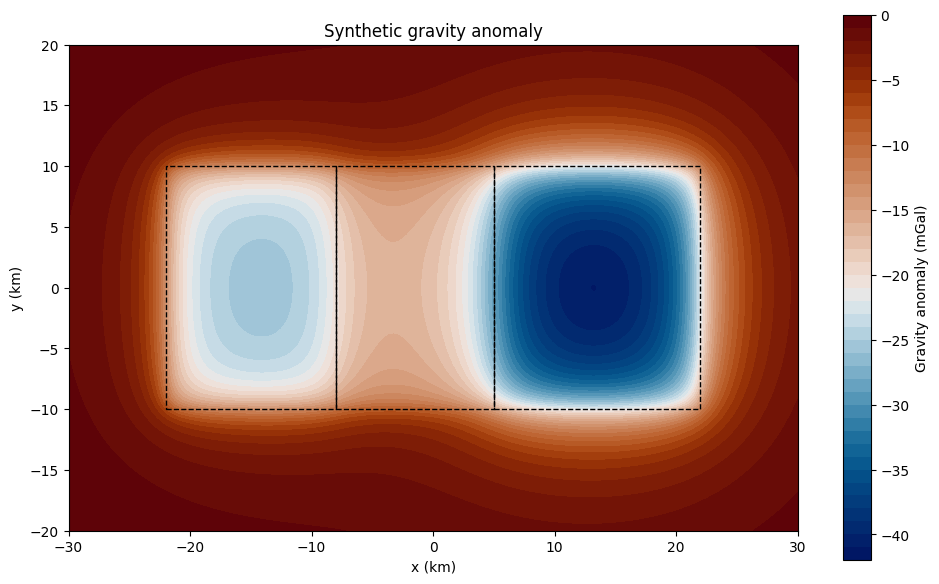

In [83]:
fig, ax = plt.subplots(figsize=(10,6))

im = ax.contourf(
    X1/1000.,
    Y1/1000.,
    gz1,
    levels=40,
    cmap=cm.vik
)

plt.colorbar(
    im,
    ax=ax,
    label="Gravity anomaly (mGal)"
)

for p in prisms1:

    xa, xb, ya, yb = p[:4]

    ax.plot(
        np.array([xa,xb,xb,xa,xa])/1000.,
        np.array([ya,ya,yb,yb,ya])/1000.,
        "k--",
        linewidth=1
    )

ax.set_xlabel("x (km)")
ax.set_ylabel("y (km)")
ax.set_title("Synthetic gravity anomaly")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

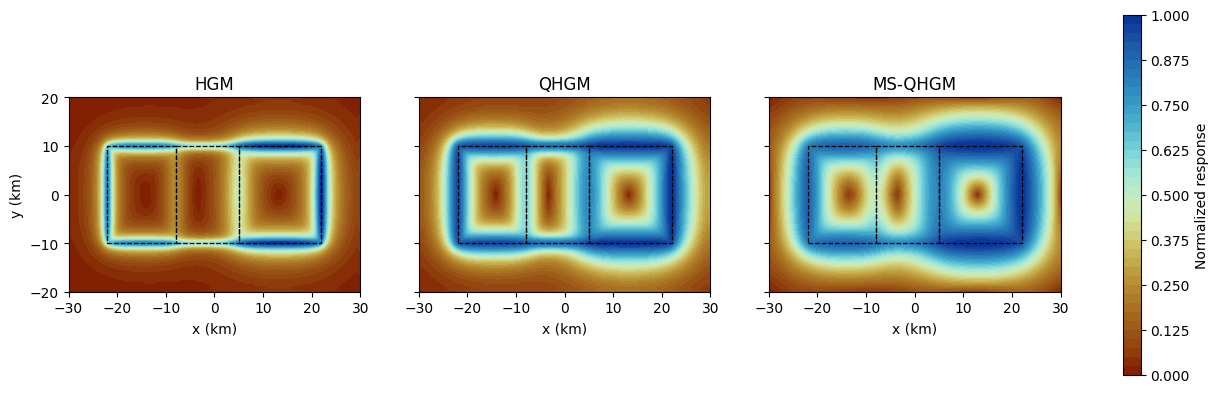

In [84]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16,5.5),
    sharex=True,
    sharey=True
)

for ax, (name, response) in zip(
    axes,
    methods1.items()
):

    im = ax.contourf(
        X1/1000.,
        Y1/1000.,
        response,
        levels=np.linspace(0,1,41),
        cmap=cm.roma
    )

    for p in prisms1:

        xa, xb, ya, yb = p[:4]

        ax.plot(
            np.array([xa,xb,xb,xa,xa])/1000.,
            np.array([ya,ya,yb,yb,ya])/1000.,
            "k--",
            linewidth=0.9
        )

    ax.set_title(name)
    ax.set_xlabel("x (km)")
    ax.set_aspect("equal")

axes[0].set_ylabel("y (km)")

fig.colorbar(
    im,
    ax=axes,
    label="Normalized response",
    shrink=0.85
)

plt.show()

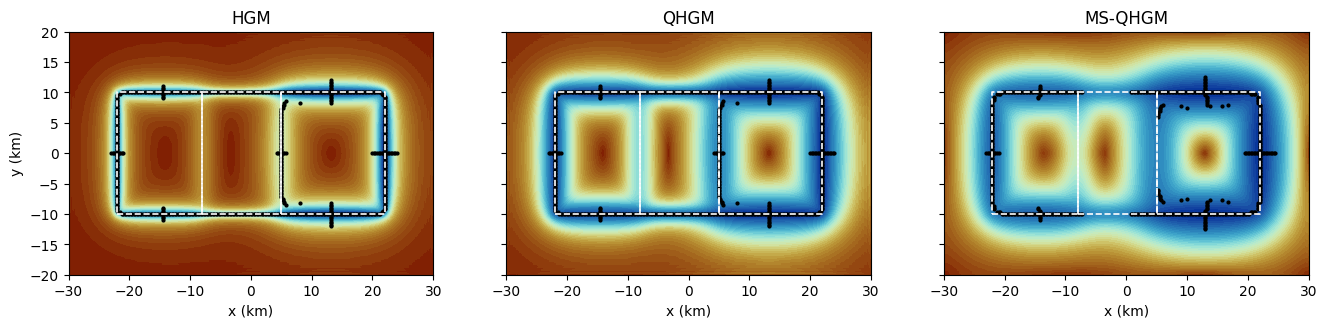

In [85]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16,5.5),
    sharex=True,
    sharey=True
)

for ax, (name, response) in zip(
    axes,
    methods1.items()
):

    ax.contourf(
        X1/1000.,
        Y1/1000.,
        response,
        levels=np.linspace(0,1,41),
        cmap=cm.roma
    )

    ridges = detected_edges1[name]

    ax.scatter(
        X1[ridges]/1000.,
        Y1[ridges]/1000.,
        s=4,
        c="black",
        label="Detected edges"
    )

    for p in prisms1:

        xa, xb, ya, yb = p[:4]

        ax.plot(
            np.array([xa,xb,xb,xa,xa])/1000.,
            np.array([ya,ya,yb,yb,ya])/1000.,
            "--",
            linewidth=1.2,
            color="white"
        )

    ax.set_title(name)
    ax.set_xlabel("x (km)")
    ax.set_aspect("equal")

axes[0].set_ylabel("y (km)")

plt.show()

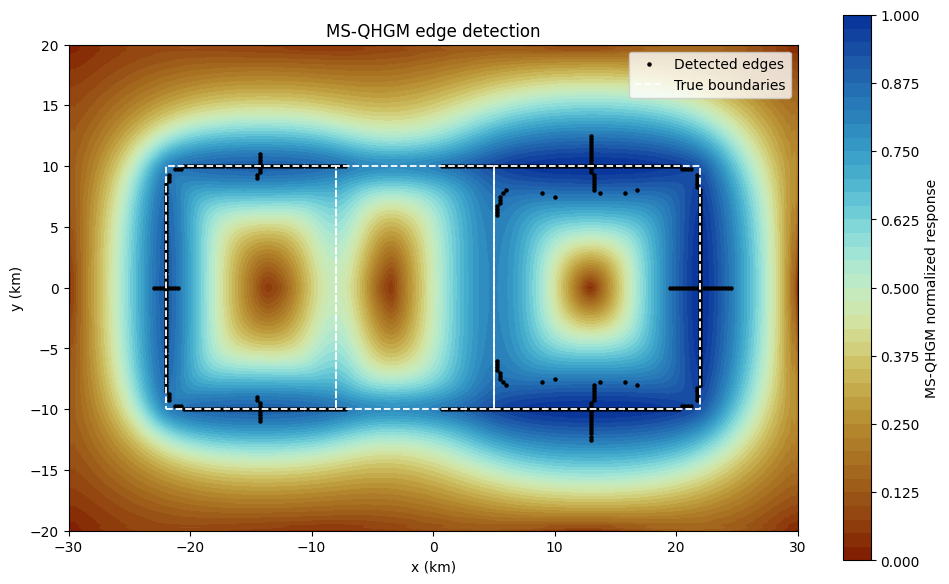

In [86]:
fig, ax = plt.subplots(figsize=(10,6))

im = ax.contourf(
    X1/1000.,
    Y1/1000.,
    MSQHGM1,
    levels=np.linspace(0,1,41),
    cmap=cm.roma
)

plt.colorbar(
    im,
    ax=ax,
    label="MS-QHGM normalized response"
)

ridges = detected_edges1["MS-QHGM"]

ax.scatter(
    X1[ridges]/1000.,
    Y1[ridges]/1000.,
    s=5,
    c="black",
    label="Detected edges"
)

for i,p in enumerate(prisms1):

    xa, xb, ya, yb = p[:4]

    ax.plot(
        np.array([xa,xb,xb,xa,xa])/1000.,
        np.array([ya,ya,yb,yb,ya])/1000.,
        "--",
        linewidth=1.3,
        color="white",
        label="True boundaries" if i == 0 else None
    )

ax.set_xlabel("x (km)")
ax.set_ylabel("y (km)")
ax.set_title("MS-QHGM edge detection")
ax.set_aspect("equal")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

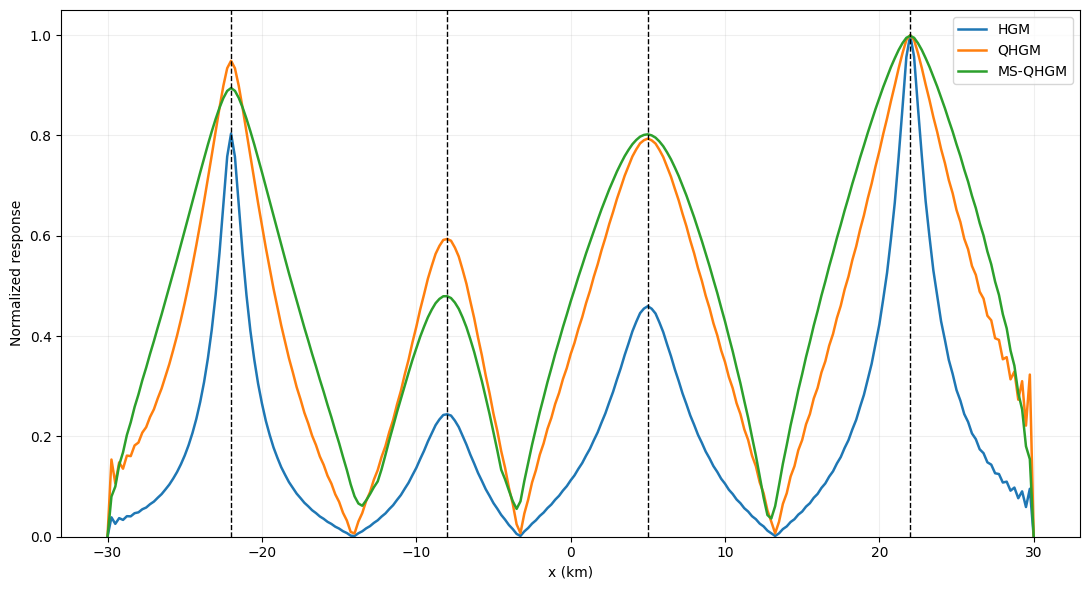

In [87]:
fig, ax = plt.subplots(figsize=(11,6))
for name, response in methods1.items():

    ax.plot(
        xv/1000.,
        response[row1,:],
        linewidth=1.8,
        label=name
    )

for edge in true_edges1:

    ax.axvline(
        edge/1000.,
        linestyle="--",
        linewidth=1.,
        color="black"
    )

ax.set_xlabel("x (km)")
ax.set_ylabel("Normalized response")
ax.set_ylim(0.,1.05)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [89]:
print("Detected edge positions (m)")
print("-"*65)

print(
    f"{'Method':<12}"
    f"{'Edge 1':>12}"
    f"{'Edge 2':>12}"
    f"{'Edge 3':>12}"
    f"{'Edge 4':>12}"
)

print("-"*65)

for name in methods1:

    d = results1[name]["detected"]

    print(f"{name:<12}"
        f"{d[0]:>12.0f}"
        f"{d[1]:>12.0f}"
        f"{d[2]:>12.0f}"
        f"{d[3]:>12.0f}")

Detected edge positions (m)
-----------------------------------------------------------------
Method            Edge 1      Edge 2      Edge 3      Edge 4
-----------------------------------------------------------------
HGM               -22000       -8000        5000       22000
QHGM              -22000       -8000        5000       22000
MS-QHGM           -22000       -8000        5000       22000


## Independent 2-D edge detection and quantitative evaluation

The previous profile-based localization test searched for maxima inside windows centered on the known structural boundaries. Although useful for diagnostic purposes, that procedure uses prior information about the true edge locations.

The present evaluation therefore extracts edge ridges directly from each two-dimensional filter response, without using the synthetic-model geometry during detection.

The true structural boundaries are introduced only after edge extraction to quantify the spatial agreement between predicted and reference edges.

For a predicted edge set $P$ and the true edge set $T$, the mean predicted-to-true distance is

$$
D_{P\rightarrow T}
=
\frac{1}{N_P}
\sum_{p\in P}
\min_{t\in T}
\|p-t\|.
$$

The complementary true-to-predicted distance is

$$
D_{T\rightarrow P}
=
\frac{1}{N_T}
\sum_{t\in T}
\min_{p\in P}
\|t-p\|.
$$

The symmetric edge-distance metric is

$$
D_{\rm sym}
=
\frac{
D_{P\rightarrow T}
+
D_{T\rightarrow P}
}{2}.
$$

The first term penalizes spurious detections located away from true structures, whereas the second penalizes missing or discontinuous detected edges.

Lower values of $D_{\rm sym}$ therefore indicate better simultaneous localization and continuity.

The response balance among the three basin compartments is retained as a complementary amplitude metric.

In [96]:
# ============================================================
# SYNTHETIC TEST 1 — INDEPENDENT 2-D EDGE EVALUATION
# ============================================================

from scipy.ndimage import distance_transform_edt

# ------------------------------------------------------------
# 1. Automatic threshold: Otsu method
# ------------------------------------------------------------

def otsu_threshold(response, nbins=256):
    r = normalize01(response)
    values = r[np.isfinite(r)]

    hist, edges = np.histogram(
        values,
        bins=nbins,
        range=(0., 1.)
    )

    centers = 0.5*(edges[:-1] + edges[1:])
    prob = hist.astype(float)/(hist.sum() + 1e-15)

    omega = np.cumsum(prob)
    mu = np.cumsum(prob*centers)
    mu_total = mu[-1]

    variance = (
        (mu_total*omega - mu)**2 /
        (omega*(1.-omega) + 1e-15)
    )

    return centers[np.nanargmax(variance)]


# ------------------------------------------------------------
# 2. Independent ridge extraction
# ------------------------------------------------------------

def detect_ridges_2d(response):
    R = normalize01(response)

    ridge_x = np.zeros_like(R, dtype=bool)
    ridge_y = np.zeros_like(R, dtype=bool)

    ridge_x[:,1:-1] = (
        (R[:,1:-1] >= R[:,:-2]) &
        (R[:,1:-1] >= R[:,2:])
    )

    ridge_y[1:-1,:] = (
        (R[1:-1,:] >= R[:-2,:]) &
        (R[1:-1,:] >= R[2:,:])
    )

    threshold = otsu_threshold(R)

    ridges = (
        (ridge_x | ridge_y) &
        (R >= threshold)
    )

    border = 4
    ridges[:border,:] = False
    ridges[-border:,:] = False
    ridges[:,:border] = False
    ridges[:,-border:] = False

    return ridges, threshold


# ------------------------------------------------------------
# 3. True structural-edge mask
# Used ONLY for evaluation
# ------------------------------------------------------------

true_mask1 = np.zeros_like(X1, dtype=bool)

tol = 0.51*max(dx, dy)

for p in prisms1:

    xa, xb, ya, yb = p[:4]

    vertical = (
        ((np.abs(X1-xa) <= tol) |
         (np.abs(X1-xb) <= tol)) &
        (Y1 >= ya-tol) &
        (Y1 <= yb+tol)
    )

    horizontal = (
        ((np.abs(Y1-ya) <= tol) |
         (np.abs(Y1-yb) <= tol)) &
        (X1 >= xa-tol) &
        (X1 <= xb+tol)
    )

    true_mask1 |= vertical | horizontal


# ------------------------------------------------------------
# 4. Symmetric 2-D edge distance
# ------------------------------------------------------------

def symmetric_edge_distance(predicted, reference, dx, dy):

    if np.sum(predicted) == 0:
        return np.nan, np.nan, np.nan

    distance_to_true = distance_transform_edt(
        ~reference,
        sampling=(dy, dx)
    )

    distance_to_pred = distance_transform_edt(
        ~predicted,
        sampling=(dy, dx)
    )

    d_pred_true = np.mean(
        distance_to_true[predicted]
    )

    d_true_pred = np.mean(
        distance_to_pred[reference]
    )

    d_sym = 0.5*(
        d_pred_true +
        d_true_pred
    )

    return d_pred_true, d_true_pred, d_sym


# ------------------------------------------------------------
# 5. Response balance
# ------------------------------------------------------------

def prism_edge_mask(prism):

    xa, xb, ya, yb = prism[:4]

    vertical = (
        ((np.abs(X1-xa) <= tol) |
         (np.abs(X1-xb) <= tol)) &
        (Y1 >= ya-tol) &
        (Y1 <= yb+tol)
    )

    horizontal = (
        ((np.abs(Y1-ya) <= tol) |
         (np.abs(Y1-yb) <= tol)) &
        (X1 >= xa-tol) &
        (X1 <= xb+tol)
    )

    return vertical | horizontal


def response_balance(response):

    amplitudes = []

    for prism in prisms1:

        mask = prism_edge_mask(prism)

        amplitudes.append(
            np.mean(response[mask])
        )

    amplitudes = np.asarray(amplitudes)

    return (
        np.min(amplitudes) /
        (np.max(amplitudes) + 1e-15)
    )


# ------------------------------------------------------------
# 6. Evaluation
# ------------------------------------------------------------

edge_results1 = {}

print(
    f"{'Method':<12}"
    f"{'Balance':>10}"
    f"{'P→T (m)':>12}"
    f"{'T→P (m)':>12}"
    f"{'Dsym (m)':>12}"
)

print("-"*58)

for name, response in methods1.items():

    ridges, threshold = detect_ridges_2d(response)

    dpt, dtp, dsym = symmetric_edge_distance(
        ridges,
        true_mask1,
        dx,
        dy
    )

    balance = response_balance(response)

    edge_results1[name] = {
        "ridges": ridges,
        "threshold": threshold,
        "balance": balance,
        "Dpt": dpt,
        "Dtp": dtp,
        "Dsym": dsym
    }

    print(
        f"{name:<12}"
        f"{balance:>10.3f}"
        f"{dpt:>12.2f}"
        f"{dtp:>12.2f}"
        f"{dsym:>12.2f}"
    )

Method         Balance     P→T (m)     T→P (m)    Dsym (m)
----------------------------------------------------------
HGM              0.580      240.29      478.52      359.40
QHGM             0.833      611.88       40.04      325.96
MS-QHGM          0.806      539.42      146.27      342.85


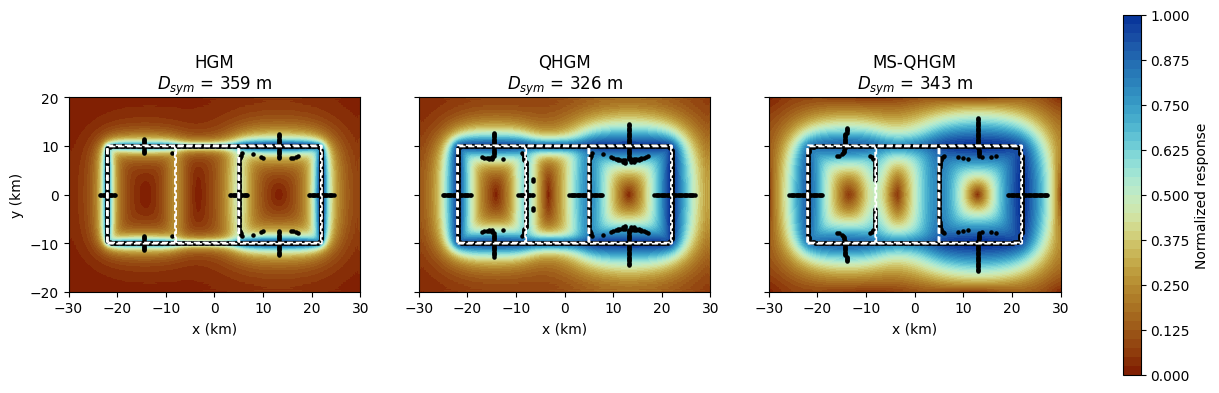

In [97]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(16,5.5),
    sharex=True,
    sharey=True
)

for ax, (name, response) in zip(
    axes,
    methods1.items()
):

    im = ax.contourf(
        X1/1000.,
        Y1/1000.,
        response,
        levels=np.linspace(0,1,41),
        cmap=cm.roma
    )

    ridges = edge_results1[name]["ridges"]

    ax.scatter(
        X1[ridges]/1000.,
        Y1[ridges]/1000.,
        s=5,
        c="black",
        label="Detected edges"
    )

    ax.contour(
        X1/1000.,
        Y1/1000.,
        true_mask1.astype(float),
        levels=[0.5],
        colors="white",
        linestyles="--",
        linewidths=1.2
    )

    ax.set_title(
        f"{name}\n"
        f"$D_{{sym}}$ = "
        f"{edge_results1[name]['Dsym']:.0f} m"
    )

    ax.set_xlabel("x (km)")
    ax.set_aspect("equal")

axes[0].set_ylabel("y (km)")

fig.colorbar(
    im,
    ax=axes,
    label="Normalized response",
    shrink=0.85
)

plt.show()

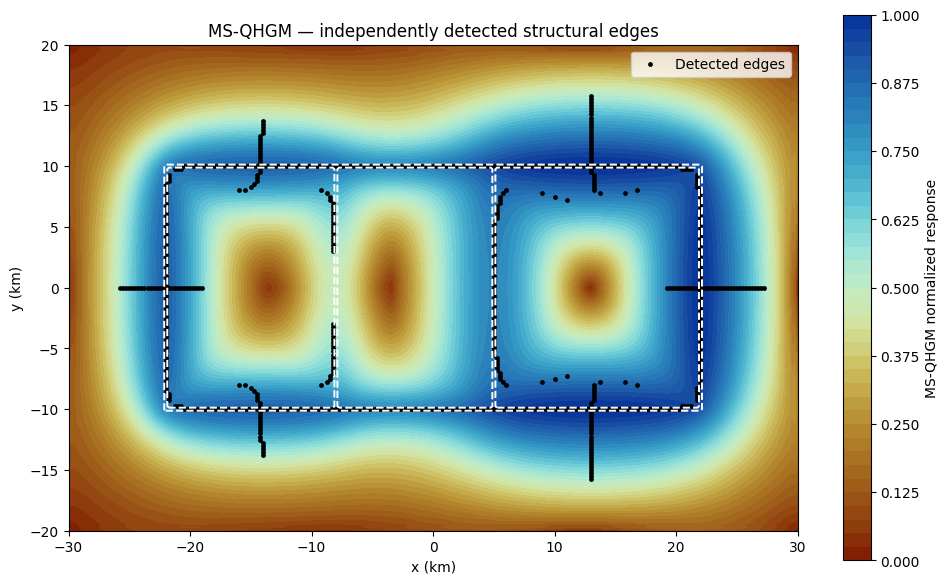

In [98]:
fig, ax = plt.subplots(figsize=(10,6))

im = ax.contourf(
    X1/1000.,
    Y1/1000.,
    MSQHGM1,
    levels=np.linspace(0,1,41),
    cmap=cm.roma
)

plt.colorbar(
    im,
    ax=ax,
    label="MS-QHGM normalized response"
)

ridges = edge_results1["MS-QHGM"]["ridges"]

ax.scatter(
    X1[ridges]/1000.,
    Y1[ridges]/1000.,
    s=6,
    c="black",
    label="Detected edges"
)

ax.contour(
    X1/1000.,
    Y1/1000.,
    true_mask1.astype(float),
    levels=[0.5],
    colors="white",
    linestyles="--",
    linewidths=1.4
)

ax.set_xlabel("x (km)")
ax.set_ylabel("y (km)")
ax.set_title(
    "MS-QHGM — independently detected structural edges"
)

ax.set_aspect("equal")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

# Synthetic Test 2 — Complex fault-controlled basin and noise robustness

The second synthetic experiment evaluates the robustness of QHGM and MS-QHGM under conditions more representative of gravity data from structurally complex sedimentary basins.

The model contains five adjacent structural compartments representing alternating depocenters, basement highs, and fault-controlled basement steps. The compartments have different lateral dimensions, different north–south extents, and substantially different basement depths. Consequently, their gravity anomalies partially overlap and interfere spatially.

The density contrast is kept constant throughout the model so that differences in filter response are controlled primarily by source geometry, depth, interference, and noise.

No parameter is recalibrated for this experiment. The formulation established during method development is retained:

$$
G_h(x,y)=
\frac{H_h(x,y)}
{H_h(x,y)+Q_{75}(H_h)},
$$

where

$$
H_h(x,y)=
\sqrt{
\left(\frac{\partial f_h}{\partial x}\right)^2+
\left(\frac{\partial f_h}{\partial y}\right)^2
}.
$$

The multiscale response is

$$
MS\text{-}QHGM(x,y)
=
N\left[
\frac{1}{K}
\sum_{k=1}^{K}G_{h_k}(x,y)
\right],
$$

with

$$
h_k=\{0,5\Delta,10\Delta,20\Delta\}.
$$

Three methods are compared:

- HGM;
- QHGM;
- MS-QHGM.

Gaussian noise is added according to

$$
f_{\rm noisy}
=
f+
\eta,
$$

with

$$
\eta\sim
\mathcal{N}
\left(
0,
\sigma_n^2
\right),
$$

and

$$
\sigma_n
=
r\,\sigma_f,
$$

where $r$ assumes the values

$$
0,\quad0.025,\quad0.05,\quad0.10.
$$

Thus, noise standard deviations correspond to 0%, 2.5%, 5%, and 10% of the standard deviation of the synthetic gravity anomaly.

For each non-zero noise level, 20 independent realizations are evaluated.

Edge extraction is performed independently from the known model geometry. The true structural boundaries are used only after detection to calculate the symmetric two-dimensional edge distance

$$
D_{\rm sym}
=
\frac{
D_{P\rightarrow T}
+
D_{T\rightarrow P}
}{2}.
$$

Two principal metrics are retained:

$$
D_{\rm sym},
$$

which measures spatial agreement and edge continuity, and

$$
Balance,
$$

which quantifies the relative ability of the filters to emphasize structures generated by compartments with substantially different depths.

The objective is to determine whether the multiscale formulation provides increasing advantages as structural interference and noise become more important.

In [107]:
# ============================================================
# SYNTHETIC TEST 2 — COMPLEX BASIN + NOISE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import distance_transform_edt
from cmcrameri import cm
from gravmag import synthetic, filtering, derivative

# ------------------------------------------------------------
# 1. Observation grid
# ------------------------------------------------------------

xmin, xmax = -35000., 35000.
ymin, ymax = -25000., 25000.
delta = 250.

xv_s2 = np.arange(xmin, xmax + delta, delta)
yv_s2 = np.arange(ymin, ymax + delta, delta)

X_s2, Y_s2 = np.meshgrid(xv_s2, yv_s2)
Z_s2 = np.zeros_like(X_s2)

# ------------------------------------------------------------
# 2. Complex fault-controlled basin
# ------------------------------------------------------------

rho = -0.25  # g/cm³

prisms_s2 = [
    [-28000., -16000., -12000.,   9000., 500., 4500., rho],
    [-16000.,  -8000.,  -9000.,  11000., 500., 2200., rho],
    [ -8000.,   5000., -14000.,  12000., 500., 6500., rho],
    [  5000.,  14000., -10000.,  13000., 500., 3000., rho],
    [ 14000.,  28000., -13000.,   8000., 500., 7500., rho]
]

gz_s2 = synthetic.my_forward_prisms_gz(
    X_s2.ravel(),
    Y_s2.ravel(),
    Z_s2.ravel(),
    prisms_s2
).reshape(X_s2.shape)

# ------------------------------------------------------------
# 3. Parameters
# ------------------------------------------------------------

eps = 1e-15
q = 75

heights_s2 = np.array([
    0.,
    5.*delta,
    10.*delta,
    20.*delta
])

# ------------------------------------------------------------
# 4. Normalization
# ------------------------------------------------------------

def normalize01_s2(a):
    a = np.asarray(a, dtype=float)

    amin = np.nanmin(a)
    amax = np.nanmax(a)

    return (a - amin)/(amax - amin + eps)

# ------------------------------------------------------------
# 5. HGM, QHGM and MS-QHGM
# ------------------------------------------------------------

def compute_methods_s2(data):

    H_scales = []
    G_scales = []

    for h in heights_s2:

        if h == 0.:
            fh = data.copy()

        else:
            fh = filtering.my_upward_continuation(
                X_s2,
                Y_s2,
                data,
                height=h,
                pad_factor=0.5,
                pad_mode="reflect",
                taper=True,
                flatten=False
            )

        fx = derivative.my_xderiv(
            X_s2,
            Y_s2,
            fh,
            n=1,
            pad_factor=0.5,
            pad_mode="reflect",
            taper=True,
            flatten=False
        )

        fy = derivative.my_yderiv(
            X_s2,
            Y_s2,
            fh,
            n=1,
            pad_factor=0.5,
            pad_mode="reflect",
            taper=True,
            flatten=False
        )

        H = np.sqrt(fx**2 + fy**2)

        lambda_q = np.nanpercentile(
            H,
            q
        )

        G = H/(H + lambda_q + eps)

        H_scales.append(H)
        G_scales.append(G)

    HGM = normalize01_s2(
        H_scales[0]
    )

    QHGM = normalize01_s2(
        G_scales[0]
    )

    MSQHGM = normalize01_s2(
        np.mean(
            np.asarray(G_scales),
            axis=0
        )
    )

    return {
        "HGM": HGM,
        "QHGM": QHGM,
        "MS-QHGM": MSQHGM
    }

# ------------------------------------------------------------
# 6. Automatic Otsu threshold
# ------------------------------------------------------------

def otsu_threshold_s2(response, nbins=256):

    r = normalize01_s2(response)

    values = r[
        np.isfinite(r)
    ]

    hist, edges = np.histogram(
        values,
        bins=nbins,
        range=(0., 1.)
    )

    centers = 0.5*(
        edges[:-1] + edges[1:]
    )

    prob = hist.astype(float)/(
        hist.sum() + eps
    )

    omega = np.cumsum(prob)

    mu = np.cumsum(
        prob*centers
    )

    mu_total = mu[-1]

    variance = (
        (mu_total*omega - mu)**2 /
        (omega*(1.-omega) + eps)
    )

    threshold = centers[
        np.nanargmax(variance)
    ]

    return float(threshold)

# ------------------------------------------------------------
# 7. Independent ridge detection
# ------------------------------------------------------------

def detect_ridges_s2(response):

    R = normalize01_s2(response)

    ridge_x = np.zeros_like(
        R,
        dtype=bool
    )

    ridge_y = np.zeros_like(
        R,
        dtype=bool
    )

    ridge_x[:,1:-1] = (
        (R[:,1:-1] >= R[:,:-2]) &
        (R[:,1:-1] >= R[:,2:])
    )

    ridge_y[1:-1,:] = (
        (R[1:-1,:] >= R[:-2,:]) &
        (R[1:-1,:] >= R[2:,:])
    )

    threshold = otsu_threshold_s2(
        R
    )

    ridges = (
        (ridge_x | ridge_y) &
        (R >= threshold)
    )

    border = 4

    ridges[:border,:] = False
    ridges[-border:,:] = False
    ridges[:,:border] = False
    ridges[:,-border:] = False

    return ridges

# ------------------------------------------------------------
# 8. True structural boundaries
# Used ONLY for evaluation
# ------------------------------------------------------------

tol = 0.51*delta

def prism_edge_mask_s2(prism):

    xa, xb, ya, yb = prism[:4]

    vertical = (
        (
            (np.abs(X_s2-xa) <= tol) |
            (np.abs(X_s2-xb) <= tol)
        ) &
        (Y_s2 >= ya-tol) &
        (Y_s2 <= yb+tol)
    )

    horizontal = (
        (
            (np.abs(Y_s2-ya) <= tol) |
            (np.abs(Y_s2-yb) <= tol)
        ) &
        (X_s2 >= xa-tol) &
        (X_s2 <= xb+tol)
    )

    return vertical | horizontal


true_mask_s2 = np.zeros_like(
    X_s2,
    dtype=bool
)

for prism in prisms_s2:

    true_mask_s2 |= prism_edge_mask_s2(
        prism
    )

# ------------------------------------------------------------
# 9. Symmetric 2-D edge distance
# ------------------------------------------------------------

def symmetric_distance_s2(predicted):

    predicted = np.asarray(
        predicted,
        dtype=bool
    )

    if np.sum(predicted) == 0:
        return np.nan

    distance_true = distance_transform_edt(
        ~true_mask_s2,
        sampling=(delta, delta)
    )

    distance_pred = distance_transform_edt(
        ~predicted,
        sampling=(delta, delta)
    )

    dpt = np.nanmean(
        distance_true[predicted]
    )

    dtp = np.nanmean(
        distance_pred[true_mask_s2]
    )

    dsym = 0.5*(
        dpt + dtp
    )

    return float(dsym)

# ------------------------------------------------------------
# 10. Response balance
# ------------------------------------------------------------

def balance_s2(response):

    values = []

    for prism in prisms_s2:

        mask = prism_edge_mask_s2(
            prism
        )

        value = np.nanmean(
            response[mask]
        )

        values.append(value)

    values = np.asarray(
        values,
        dtype=float
    )

    vmax = np.nanmax(values)
    vmin = np.nanmin(values)

    if (
        not np.isfinite(vmax)
        or vmax <= 0.
    ):
        return np.nan

    balance = vmin/(
        vmax + eps
    )

    return float(balance)

# ------------------------------------------------------------
# 11. Clean-data results
# ------------------------------------------------------------

methods_clean_s2 = compute_methods_s2(
    gz_s2
)

clean_results_s2 = {}

print("CLEAN DATA")

print(
    f"{'Method':<12}"
    f"{'Balance':>12}"
    f"{'Dsym (m)':>14}"
)

print("-"*38)

for name, response in methods_clean_s2.items():

    ridges = detect_ridges_s2(
        response
    )

    balance = balance_s2(
        response
    )

    dsym = symmetric_distance_s2(
        ridges
    )

    clean_results_s2[name] = {
        "balance": balance,
        "dsym": dsym,
        "ridges": ridges
    }

    print(
        f"{name:<12}"
        f"{balance:>12.3f}"
        f"{dsym:>14.2f}"
    )

# ------------------------------------------------------------
# 12. Monte Carlo noise experiment
# ------------------------------------------------------------

noise_levels = [
    0.,
    0.025,
    0.05,
    0.10
]

nreal = 20

field_std = np.nanstd(
    gz_s2
)

noise_results_s2 = {}

for noise_level in noise_levels:

    noise_results_s2[
        noise_level
    ] = {}

    for name in [
        "HGM",
        "QHGM",
        "MS-QHGM"
    ]:

        noise_results_s2[
            noise_level
        ][name] = {
            "balance": [],
            "dsym": []
        }

    if noise_level == 0.:
        n_current = 1
    else:
        n_current = nreal

    rng = np.random.default_rng(
        1000 +
        int(noise_level*10000)
    )

    for realization in range(
        n_current
    ):

        if noise_level == 0.:

            data = gz_s2.copy()

        else:

            noise = rng.normal(
                0.,
                noise_level*field_std,
                gz_s2.shape
            )

            data = (
                gz_s2 +
                noise
            )

        methods = compute_methods_s2(
            data
        )

        for name, response in methods.items():

            ridges = detect_ridges_s2(
                response
            )

            balance = balance_s2(
                response
            )

            dsym = symmetric_distance_s2(
                ridges
            )

            noise_results_s2[
                noise_level
            ][name]["balance"].append(
                balance
            )

            noise_results_s2[
                noise_level
            ][name]["dsym"].append(
                dsym
            )

CLEAN DATA
Method           Balance      Dsym (m)
--------------------------------------
HGM                0.557        624.12
QHGM               0.819        455.57
MS-QHGM            0.805        403.36


In [108]:
print()
print("NOISE ROBUSTNESS")

print(
    f"{'Noise':>7}"
    f"{'Method':>12}"
    f"{'Balance':>18}"
    f"{'Dsym (m)':>22}"
)

print("-"*59)

for noise_level in noise_levels:

    for name in [
        "HGM",
        "QHGM",
        "MS-QHGM"
    ]:

        b = np.asarray(
            noise_results_s2[
                noise_level
            ][name]["balance"],
            dtype=float
        )

        d = np.asarray(
            noise_results_s2[
                noise_level
            ][name]["dsym"],
            dtype=float
        )

        print(
            f"{100*noise_level:6.1f}% "
            f"{name:>11} "
            f"{np.nanmean(b):8.3f} ± "
            f"{np.nanstd(b):.3f} "
            f"{np.nanmean(d):9.2f} ± "
            f"{np.nanstd(d):.2f}"
        )


NOISE ROBUSTNESS
  Noise      Method           Balance              Dsym (m)
-----------------------------------------------------------
   0.0%         HGM    0.557 ± 0.000    624.12 ± 0.00
   0.0%        QHGM    0.819 ± 0.000    455.57 ± 0.00
   0.0%     MS-QHGM    0.805 ± 0.000    403.36 ± 0.00
   2.5%         HGM    0.662 ± 0.021   1982.94 ± 12.92
   2.5%        QHGM    0.812 ± 0.015   2217.99 ± 6.25
   2.5%     MS-QHGM    0.800 ± 0.004   1339.20 ± 5.77
   5.0%         HGM    0.815 ± 0.025   2221.36 ± 8.63
   5.0%        QHGM    0.894 ± 0.014   2295.99 ± 5.79
   5.0%     MS-QHGM    0.818 ± 0.004   1376.49 ± 6.34
  10.0%         HGM    0.909 ± 0.035   2320.92 ± 11.12
  10.0%        QHGM    0.947 ± 0.019   2334.72 ± 6.95
  10.0%     MS-QHGM    0.831 ± 0.007   1392.82 ± 8.04


In [109]:
import os
import numpy as np
import matplotlib.pyplot as plt

outdir = "results"
os.makedirs(outdir, exist_ok=True)

def pick_first(options, scope):
    """Retorna a primeira variável existente em 'scope'."""
    for name in options:
        if name in scope:
            return scope[name], name
    return None, None

def compute_edge_mask_from_model(model):
    """
    Extrai uma borda aproximada a partir do modelo sintético.
    Funciona bem para modelos binários/multibloco.
    """
    mask = np.isfinite(model) & (np.abs(model) > 0)
    edge = np.zeros_like(mask, dtype=bool)

    edge[:-1, :] |= (mask[:-1, :] != mask[1:, :])
    edge[1:,  :] |= (mask[:-1, :] != mask[1:, :])

    edge[:, :-1] |= (mask[:, :-1] != mask[:, 1:])
    edge[:, 1: ] |= (mask[:, :-1] != mask[:, 1:])

    return edge

def ridge_to_points(ridges, X, Y):
    """
    Converte a saída de detect_ridges_s2(...) para pontos x,y.
    Aceita:
    - máscara booleana 2D
    - tupla/lista de índices
    - array Nx2
    """
    if ridges is None:
        return np.array([]), np.array([])

    # Caso seja máscara booleana
    if isinstance(ridges, np.ndarray) and ridges.dtype == bool and ridges.ndim == 2:
        iy, ix = np.where(ridges)
        return X[iy, ix], Y[iy, ix]

    # Caso seja array Nx2
    if isinstance(ridges, np.ndarray) and ridges.ndim == 2 and ridges.shape[1] == 2:
        iy = ridges[:, 0].astype(int)
        ix = ridges[:, 1].astype(int)
        return X[iy, ix], Y[iy, ix]

    # Caso seja tupla/lista de índices
    if isinstance(ridges, (tuple, list)) and len(ridges) == 2:
        iy = np.asarray(ridges[0]).astype(int)
        ix = np.asarray(ridges[1]).astype(int)
        return X[iy, ix], Y[iy, ix]

    return np.array([]), np.array([])

def safe_contour_levels(A, n=16):
    a = np.asarray(A, dtype=float)
    vmin = np.nanpercentile(a, 2)
    vmax = np.nanpercentile(a, 98)
    if np.isclose(vmin, vmax):
        vmin = np.nanmin(a)
        vmax = np.nanmax(a)
    return np.linspace(vmin, vmax, n)

In [110]:
scope = globals()

# grade
X, X_name = pick_first(["X2", "XX2", "X_s2", "Xp2", "X"], scope)
Y, Y_name = pick_first(["Y2", "YY2", "Y_s2", "Yp2", "Y"], scope)

# modelo sintético (densidade, prisma, etc.)
model_s2, model_name = pick_first(
    ["model_s2", "rho_true_s2", "density_s2", "mtrue_s2", "synthetic_model_s2"],
    scope
)

# dado observado / campo sintético
field_s2, field_name = pick_first(
    ["gz_s2", "g_s2", "data_s2", "field_s2", "anomaly_s2", "obs_s2"],
    scope
)

# respostas dos métodos (esperado: dict com HGM, QHGM, MS-QHGM)
methods_clean_s2, methods_name = pick_first(
    ["methods_clean_s2", "responses_clean_s2", "methods_s2"],
    scope
)

if X is None or Y is None:
    raise ValueError(
        "Não encontrei as malhas X e Y. "
        "Ajuste os nomes no bloco ENTRADAS."
    )

if methods_clean_s2 is None:
    raise ValueError(
        "Não encontrei o dicionário methods_clean_s2. "
        "Ajuste os nomes no bloco ENTRADAS."
    )

# borda verdadeira a partir do modelo, se houver
true_edge = None
if model_s2 is not None:
    true_edge = compute_edge_mask_from_model(model_s2)

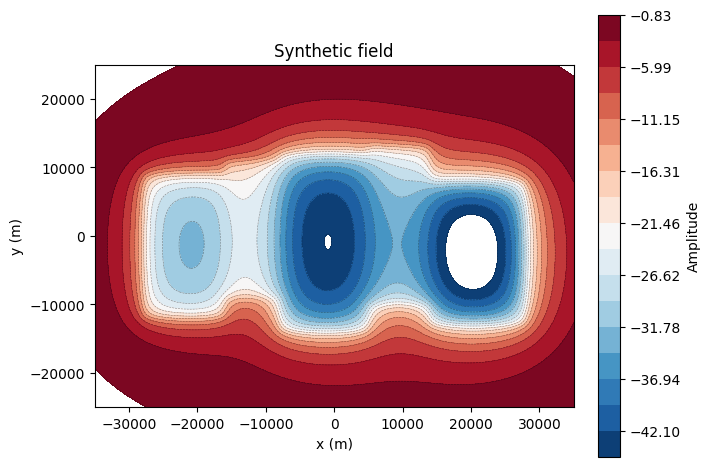

Figura salva em: results\test2_model_and_field.png


In [111]:
if (model_s2 is not None) or (field_s2 is not None):

    ncols = 0
    if model_s2 is not None:
        ncols += 1
    if field_s2 is not None:
        ncols += 1

    fig, axes = plt.subplots(1, ncols, figsize=(7*ncols, 5), constrained_layout=True)
    if ncols == 1:
        axes = [axes]

    k = 0

    if model_s2 is not None:
        ax = axes[k]
        lev = safe_contour_levels(model_s2, n=18)
        cf = ax.contourf(X, Y, model_s2, levels=lev, cmap="viridis")
        ax.contour(X, Y, model_s2, levels=lev, colors="k", linewidths=0.4, alpha=0.45)
        if true_edge is not None:
            ax.contour(X, Y, true_edge.astype(int), levels=[0.5],
                       colors="w", linewidths=1.5, linestyles="--")
        ax.set_title("Synthetic model")
        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")
        ax.set_aspect("equal")
        plt.colorbar(cf, ax=ax, shrink=0.9, label="Density / model")
        k += 1

    if field_s2 is not None:
        ax = axes[k]
        lev = safe_contour_levels(field_s2, n=18)
        cf = ax.contourf(X, Y, field_s2, levels=lev, cmap="RdBu_r")
        ax.contour(X, Y, field_s2, levels=lev, colors="k", linewidths=0.4, alpha=0.45)
        if true_edge is not None:
            ax.contour(X, Y, true_edge.astype(int), levels=[0.5],
                       colors="yellow", linewidths=1.4, linestyles="--")
        ax.set_title("Synthetic field")
        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")
        ax.set_aspect("equal")
        plt.colorbar(cf, ax=ax, shrink=0.9, label="Amplitude")
        k += 1

    f1 = os.path.join(outdir, "test2_model_and_field.png")
    plt.savefig(f1, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Figura salva em: {f1}")

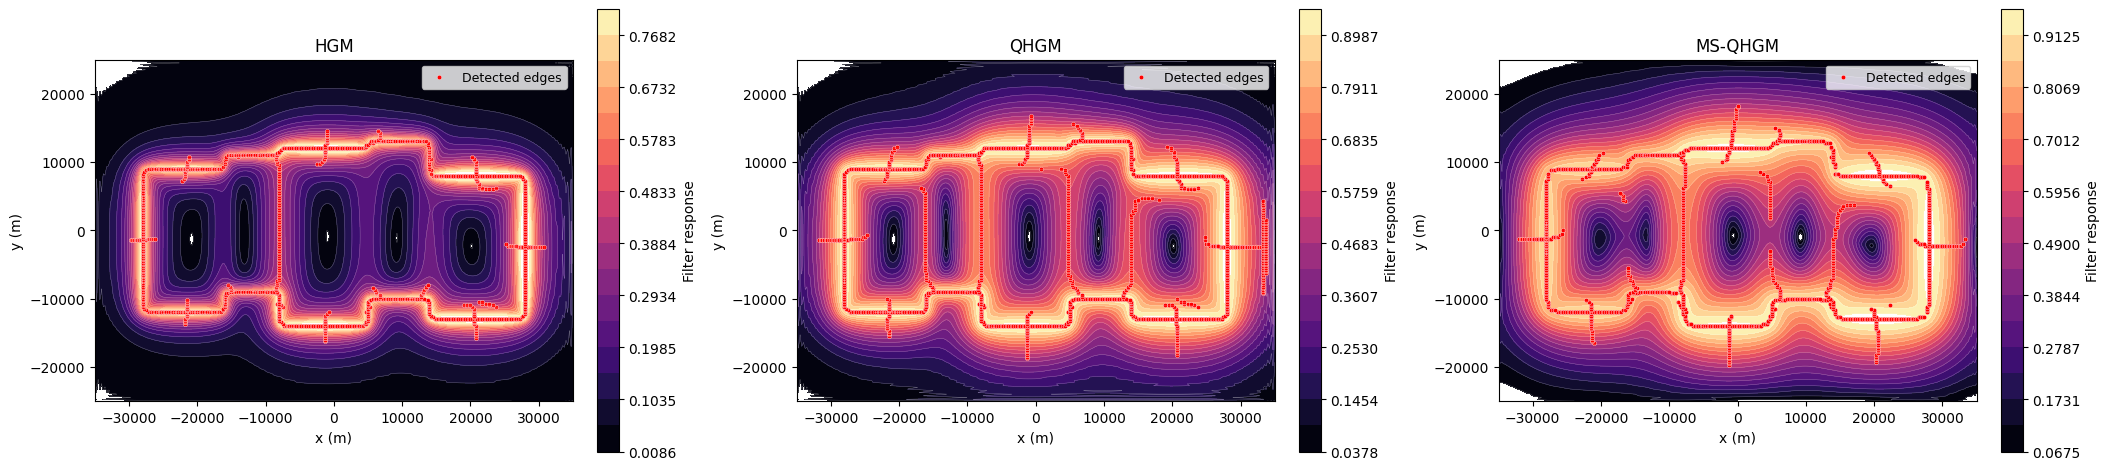

Figura salva em: results\test2_filter_maps_detected_edges.png


In [112]:
method_order = ["HGM", "QHGM", "MS-QHGM"]
available_methods = [m for m in method_order if m in methods_clean_s2]

if len(available_methods) == 0:
    available_methods = list(methods_clean_s2.keys())

fig, axes = plt.subplots(1, len(available_methods),
                         figsize=(7*len(available_methods), 5),
                         constrained_layout=True)

if len(available_methods) == 1:
    axes = [axes]

for ax, name in zip(axes, available_methods):
    response = methods_clean_s2[name]

    lev = safe_contour_levels(response, n=18)
    cf = ax.contourf(X, Y, response, levels=lev, cmap="magma")
    ax.contour(X, Y, response, levels=lev, colors="w", linewidths=0.35, alpha=0.35)

    # borda verdadeira
    if true_edge is not None:
        ax.contour(X, Y, true_edge.astype(int), levels=[0.5],
                   colors="cyan", linewidths=1.5, linestyles="--")

    # borda detectada
    ridges = detect_ridges_s2(response)
    xr, yr = ridge_to_points(ridges, X, Y)
    if len(xr) > 0:
        ax.scatter(xr, yr, s=10, c="red", edgecolors="white", linewidths=0.25,
                   label="Detected edges")

    ax.set_title(name)
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_aspect("equal")
    ax.legend(loc="upper right", fontsize=9)

    cbar = plt.colorbar(cf, ax=ax, shrink=0.9)
    cbar.set_label("Filter response")

f2 = os.path.join(outdir, "test2_filter_maps_detected_edges.png")
plt.savefig(f2, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figura salva em: {f2}")

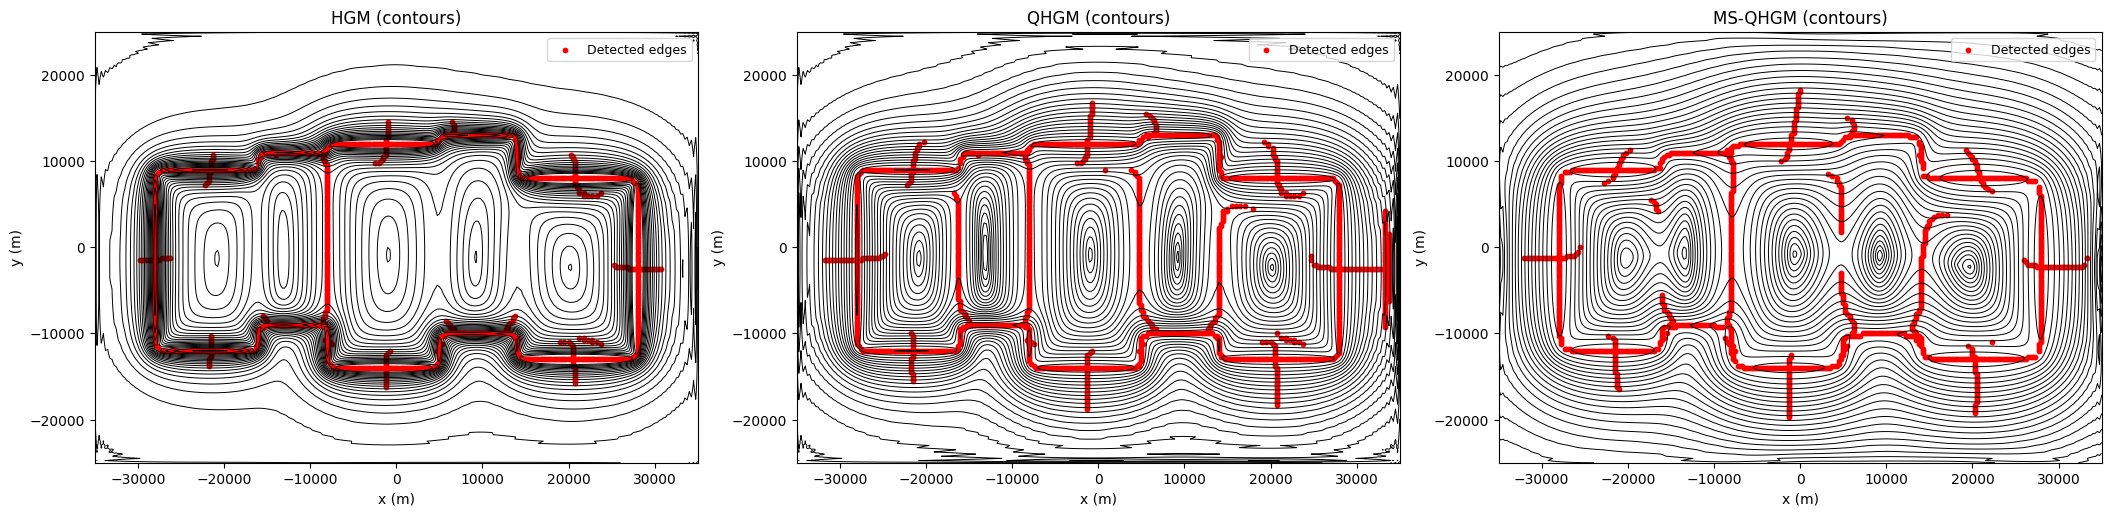

Figura salva em: results\test2_contours_only_detected_edges.png


In [113]:
fig, axes = plt.subplots(1, len(available_methods),
                         figsize=(7*len(available_methods), 5),
                         constrained_layout=True)

if len(available_methods) == 1:
    axes = [axes]

for ax, name in zip(axes, available_methods):
    response = methods_clean_s2[name]

    lev = safe_contour_levels(response, n=20)
    ax.contour(X, Y, response, levels=lev, colors="k", linewidths=0.7)

    if true_edge is not None:
        ax.contour(X, Y, true_edge.astype(int), levels=[0.5],
                   colors="blue", linewidths=1.6, linestyles="--")

    ridges = detect_ridges_s2(response)
    xr, yr = ridge_to_points(ridges, X, Y)
    if len(xr) > 0:
        ax.scatter(xr, yr, s=10, c="red", label="Detected edges")

    ax.set_title(f"{name} (contours)")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_aspect("equal")
    ax.legend(loc="upper right", fontsize=9)

f3 = os.path.join(outdir, "test2_contours_only_detected_edges.png")
plt.savefig(f3, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figura salva em: {f3}")

In [114]:
methods_order = ["HGM", "QHGM", "MS-QHGM"]
noise_percent = np.array(noise_levels, dtype=float) * 100.0
noise_stats = {}

for name in methods_order:
    mean_dsym = []
    std_dsym = []
    mean_balance = []
    std_balance = []

    for level in noise_levels:

        d = np.asarray(
            noise_results_s2[level][name]["dsym"],
            dtype=float
        )

        b = np.asarray(
            noise_results_s2[level][name]["balance"],
            dtype=float
        )

        mean_dsym.append(np.nanmean(d))
        std_dsym.append(np.nanstd(d))

        mean_balance.append(np.nanmean(b))
        std_balance.append(np.nanstd(b))

    noise_stats[name] = {
        "mean_dsym": np.asarray(mean_dsym),
        "std_dsym": np.asarray(std_dsym),
        "mean_balance": np.asarray(mean_balance),
        "std_balance": np.asarray(std_balance)
    }

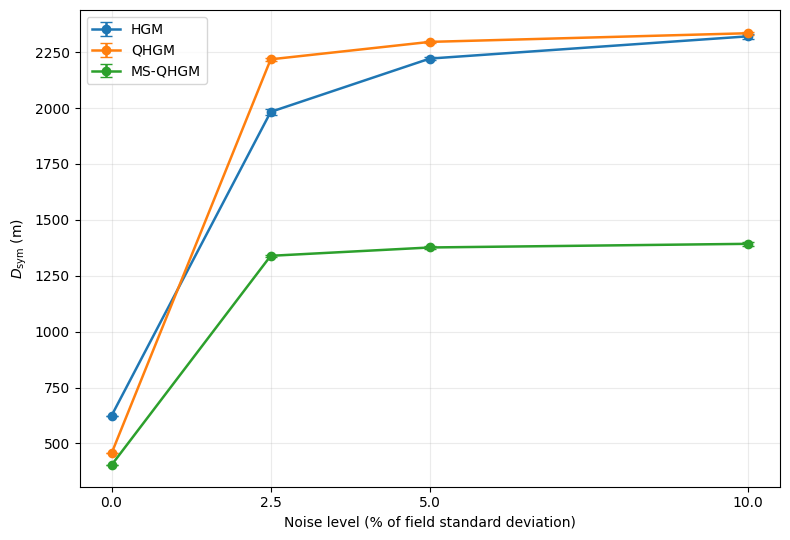

Figura salva em: results\test2_noise_dsym.png


In [115]:
fig, ax = plt.subplots(figsize=(8, 5.5))

for name in methods_order:

    stats = noise_stats[name]

    ax.errorbar(
        noise_percent,
        stats["mean_dsym"],
        yerr=stats["std_dsym"],
        marker="o",
        linewidth=1.8,
        capsize=4,
        label=name
    )

ax.set_xlabel(
    "Noise level (% of field standard deviation)"
)

ax.set_ylabel(
    r"$D_{\rm sym}$ (m)"
)

ax.set_xticks(
    noise_percent
)

ax.grid(
    alpha=0.25
)

ax.legend()

plt.tight_layout()

f1 = os.path.join(
    outdir,
    "test2_noise_dsym.png"
)

plt.savefig(
    f1,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:", f1)

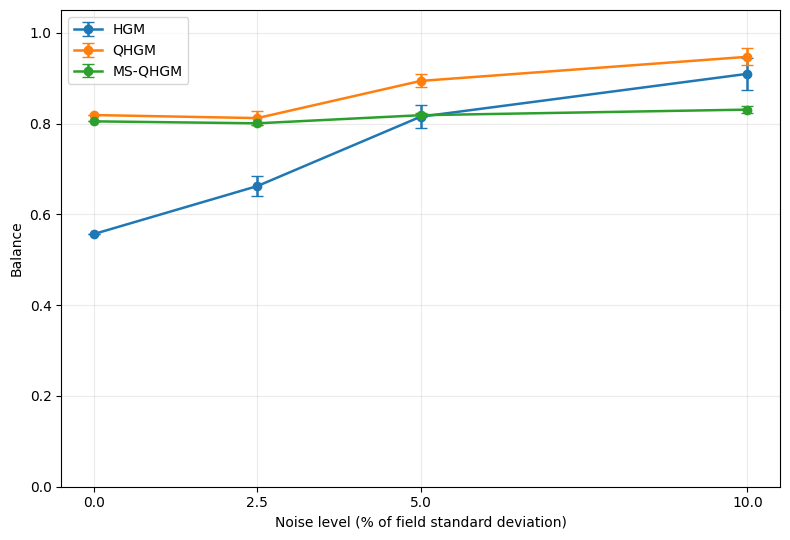

Figura salva em: results\test2_noise_balance.png


In [116]:
fig, ax = plt.subplots(figsize=(8, 5.5))

for name in methods_order:

    stats = noise_stats[name]

    ax.errorbar(
        noise_percent,
        stats["mean_balance"],
        yerr=stats["std_balance"],
        marker="o",
        linewidth=1.8,
        capsize=4,
        label=name
    )

ax.set_xlabel(
    "Noise level (% of field standard deviation)"
)

ax.set_ylabel(
    "Balance"
)

ax.set_xticks(
    noise_percent
)

ax.set_ylim(
    0,
    1.05
)

ax.grid(
    alpha=0.25
)

ax.legend()

plt.tight_layout()

f2 = os.path.join(
    outdir,
    "test2_noise_balance.png"
)

plt.savefig(
    f2,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:", f2)

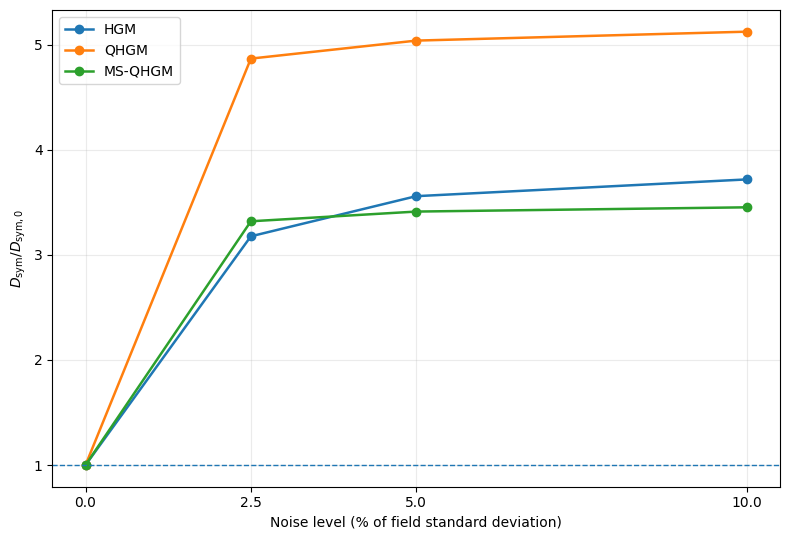

Figura salva em: results\test2_noise_relative_dsym.png


In [117]:
fig, ax = plt.subplots(figsize=(8, 5.5))

for name in methods_order:

    stats = noise_stats[name]

    baseline = stats["mean_dsym"][0]

    relative = (
        stats["mean_dsym"] /
        baseline
    )

    ax.plot(
        noise_percent,
        relative,
        marker="o",
        linewidth=1.8,
        label=name
    )

ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1.0
)

ax.set_xlabel(
    "Noise level (% of field standard deviation)"
)

ax.set_ylabel(
    r"$D_{\rm sym}/D_{\rm sym,0}$"
)

ax.set_xticks(
    noise_percent
)

ax.grid(
    alpha=0.25
)

ax.legend()

plt.tight_layout()

f3 = os.path.join(
    outdir,
    "test2_noise_relative_dsym.png"
)

plt.savefig(
    f3,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:", f3)

In [118]:
print()
print(
    f"{'Noise':>7}"
    f"{'Method':>12}"
    f"{'Balance':>18}"
    f"{'Dsym (m)':>22}"
    f"{'D/D0':>12}"
)

print("-"*71)

for i, level in enumerate(noise_levels):

    for name in methods_order:

        stats = noise_stats[name]

        bmean = stats["mean_balance"][i]
        bstd = stats["std_balance"][i]

        dmean = stats["mean_dsym"][i]
        dstd = stats["std_dsym"][i]

        rel = (
            dmean /
            stats["mean_dsym"][0]
        )

        print(
            f"{100*level:6.1f}% "
            f"{name:>11} "
            f"{bmean:8.3f} ± {bstd:.3f} "
            f"{dmean:9.2f} ± {dstd:.2f} "
            f"{rel:10.3f}"
        )


  Noise      Method           Balance              Dsym (m)        D/D0
-----------------------------------------------------------------------
   0.0%         HGM    0.557 ± 0.000    624.12 ± 0.00      1.000
   0.0%        QHGM    0.819 ± 0.000    455.57 ± 0.00      1.000
   0.0%     MS-QHGM    0.805 ± 0.000    403.36 ± 0.00      1.000
   2.5%         HGM    0.662 ± 0.021   1982.94 ± 12.92      3.177
   2.5%        QHGM    0.812 ± 0.015   2217.99 ± 6.25      4.869
   2.5%     MS-QHGM    0.800 ± 0.004   1339.20 ± 5.77      3.320
   5.0%         HGM    0.815 ± 0.025   2221.36 ± 8.63      3.559
   5.0%        QHGM    0.894 ± 0.014   2295.99 ± 5.79      5.040
   5.0%     MS-QHGM    0.818 ± 0.004   1376.49 ± 6.34      3.413
  10.0%         HGM    0.909 ± 0.035   2320.92 ± 11.12      3.719
  10.0%        QHGM    0.947 ± 0.019   2334.72 ± 6.95      5.125
  10.0%     MS-QHGM    0.831 ± 0.007   1392.82 ± 8.04      3.453
